In [1]:
from Functions import *
from Rewiring_functions import *
import itertools

In [2]:
filename1="./DATA/clough_data.csv"
filename2="./DATA/clough_pairwise_distance.csv"
filename3="./DATA/landscvars.csv"

In [3]:
df1 = pd.read_csv(
    filename1, sep=";", decimal=",",index_col=0)

In [4]:
df1[df1["Network_id"]=="TAG"]

,Study_id,Network_id,Sampling_method,Authors_habitat,EuPPollNet_habitat,Bioregion,Country,Locality,Latitude,Longitude,...,Pollinator_original_name,Pollinator_accepted_name,Pollinator_rank,Pollinator_order,Pollinator_family,Pollinator_genus,Pollinator_unsure_id,Pollinator_uncertainty_type,Flower_data,Flower_data_merger
2168,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Saltella sphondylii (Schrank,1803)",Saltella sphondylii,SPECIES,Diptera,Sepsidae,Saltella,No,NaN,Yes,RanunculusacrisNATAG_202017-6-2020
2169,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Saltella sphondylii (Schrank,1803)",Saltella sphondylii,SPECIES,Diptera,Sepsidae,Saltella,No,NaN,Yes,RanunculusacrisNATAG_202017-6-2020
2170,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Acupalpus exiguus Dejean,1829",Acupalpus exiguus,SPECIES,Coleoptera,Carabidae,Acupalpus,No,NaN,Yes,RanunculusacrisNATAG_202017-6-2020
2171,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Bombus lapidarius (Linnaeus,1758)",Bombus lapidarius,SPECIES,Hymenoptera,Apidae,Bombus,No,NaN,Yes,TrifoliumrepensNATAG_202017-6-2020
2172,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Halictus tumulorum (Linnaeus,1758)",Seladonia tumulorum,SPECIES,Hymenoptera,Halictidae,Seladonia,No,NaN,Yes,PotentillareptansNATAG_202017-6-2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2282,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,Unidentified Diptera,Diptera,ORDER,Diptera,NaN,NaN,No,NaN,Yes,GaliumverumNATAG_202120-8-2021
2283,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,"Lycaena phlaeas (Linnaeus,1761)",Lycaena phlaeas,SPECIES,Lepidoptera,Lycaenidae,Lycaena,No,NaN,Yes,AchilleaptarmicaNATAG_202119-7-2021
2284,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,Unidentified Syrphidae,Syrphidae,FAMILY,Diptera,Syrphidae,NaN,No,NaN,Yes,CentaureajaceaNATAG_202119-7-2021
2285,11_Clough,TAG,Plot,grassland,Intensive grasslands,Continental,Sweden,Scania,55.931706,12.936524,...,Bombus cryptarum/lucorum/magnus/terrestris,Bombus terrestris,SPECIES,Hymenoptera,Apidae,Bombus,Yes,species_complex,Yes,CentaureajaceaNATAG_202119-7-2021


In [5]:
#hay 18 redes en el estudio de Clough, vamos a ver los tamaños de cada una y tal 
df1["Network_id"].value_counts()
#df1["Network_id"].nunique()

TOM    296
HAM    262
STE    219
DAL    193
LYB    185
KAR    178
SPJ    176
KAG    158
PET    130
TAG    119
HAR    111
KOM    105
ASK     91
GLA     87
ROR     74
LOB     70
HAS     66
GYL     62
Name: Network_id, dtype: int64

# Descripción de redes

In [6]:
# Resumen de cada red
network_summary = (
    df1.groupby("Network_id")
    .agg(
        n_plants=("Plant_accepted_name", "nunique"),
        n_pollinators=("Pollinator_accepted_name", "nunique"),
        n_interactions=("Interaction", "count")
    )
    .reset_index()
)
network_summary = network_summary.sort_values(
    by="n_interactions",
    ascending=False
).reset_index(drop=True)

print(network_summary)

latex_table = network_summary.to_latex(
    index=False,
    column_format="llll",
    header=["Network ID", "Plant sp.", "Pollinator sp.", "Interactions"],
    caption=r"\textbf{Summary statistics of the interaction networks.} From left to right, columns indicate network ID, number of different plant species recorded, number of pollinator species recorded, and number of unique interactions recorded.",
    label="tab:network_summary",
    escape=False
)

with open("spatail_networks.tex", "w") as f:
    f.write(latex_table)



   Network_id  n_plants  n_pollinators  n_interactions
0         TOM        12             64             296
1         HAM        12             49             262
2         STE         7             37             219
3         DAL        12             39             193
4         LYB        15             39             185
5         KAR        10             46             178
6         SPJ         9             55             176
7         KAG         9             44             158
8         PET        17             51             130
9         TAG        17             45             119
10        HAR         9             30             111
11        KOM        12             36             105
12        ASK        10             34              91
13        GLA         9             36              87
14        ROR        10             34              74
15        LOB        16             27              70
16        HAS         7             36              66
17        

/tmp/ipykernel_6346/2277898699.py:18: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  latex_table = network_summary.to_latex(


# construccion de redes de cada sitio

guardamos en matrixform

In [7]:
Sites = list(df1["Network_id"].unique())

networks = {}

for site in Sites:

    # Filtrar por red
    network_df = df1[df1["Network_id"] == site]

    # Agrupar por par planta-polinizador y sumar interacciones
    interactions = (
        network_df
        .groupby([
            "Plant_accepted_name",
            "Pollinator_accepted_name"
        ])["Interaction"]
        .sum()
        .reset_index()
    )

    # Construir matriz de interacción
    Imat = (
        interactions
        .pivot(
            index="Plant_accepted_name",
            columns="Pollinator_accepted_name",
            values="Interaction"
        )
        .fillna(0)
    )

    networks[site] = Imat

In [8]:
networks

{'ASK': Pollinator_accepted_name  Andrena subopaca  Anthomyiidae  Bombus soroeensis  \
 Plant_accepted_name                                                           
 Achillea millefolium                   0.0           0.0                0.0   
 Campanula rotundifolia                 0.0           0.0                1.0   
 Cerastium fontanum                     0.0           0.0                0.0   
 Galium saxatile                        0.0           0.0                0.0   
 Pilosella officinarum                  0.0           2.0                0.0   
 Potentilla erecta                      1.0           0.0                0.0   
 Stellaria graminea                     0.0           0.0                0.0   
 Trifolium pratense                     0.0           0.0                0.0   
 Trifolium repens                       0.0           0.0                0.0   
 Veronica chamaedrys                    0.0           0.0                0.0   
 
 Pollinator_accepted_name  Bras

# Distancias y eleccion de redes

In [9]:
df_dist = pd.read_csv(filename2, sep=";", decimal="," , index_col=0)

In [10]:
df_dist

,Network_1,Latitude_1,Longitude_1,Network_2,Latitude_2,Longitude_2,Distance_km
1,GYL,55.610051,14.195980,ROR,55.623028,14.245724,3.451314
2,KAR,55.898692,13.359820,STE,55.878760,13.420302,4.387153
3,GYL,55.610051,14.195980,KOM,55.578677,14.148723,4.591010
4,SPJ,55.585363,14.030200,TOM,55.540414,14.016585,5.077535
5,HAS,55.940827,13.395099,KAR,55.898692,13.359820,5.183956
...,...,...,...,...,...,...,...
149,GYL,55.610051,14.195980,TAG,55.931706,12.936524,86.777745
150,ROR,55.623028,14.245724,TAG,55.931706,12.936524,89.050664
151,HAM,55.491926,14.159066,TAG,55.931706,12.936524,91.116054
152,GLA,55.574799,14.273677,TAG,55.931706,12.936524,92.886174


In [11]:
# Distancia media de cada red al resto
dist_mean = pd.concat([
    df_dist[["Network_1", "Distance_km"]].rename(
        columns={"Network_1": "Network_id"}
    ),
    df_dist[["Network_2", "Distance_km"]].rename(
        columns={"Network_2": "Network_id"}
    )
]).groupby("Network_id")["Distance_km"].mean().sort_values(ascending=False)

print(dist_mean)

Network_id
TAG    57.952879
KAG    50.029668
ASK    45.445304
PET    45.235133
HAM    43.812537
GLA    43.645930
ROR    41.684682
HAS    40.053711
HAR    40.033217
GYL    39.686342
KOM    38.792389
KAR    38.507541
DAL    38.314941
TOM    38.157979
STE    36.630422
SPJ    36.466856
LYB    33.596038
LOB    32.955948
Name: Distance_km, dtype: float64


In [12]:
#ordenar las redes , apra coger solo 1

site="TAG" #por ejemplo elegimos la más periferica TAG, o la mas grande TOM

# Redes donde site aparece como Network_1
d1 = df_dist[df_dist["Network_1"] == site][
    ["Network_2", "Distance_km"]
].rename(columns={"Network_2": "Network"})

# Redes donde site aparece como Network_2
d2 = df_dist[df_dist["Network_2"] == site][
    ["Network_1", "Distance_km"]
].rename(columns={"Network_1": "Network"})

# Unir ambas
distances = pd.concat([d1, d2])

# Ordenar por distancia creciente
distances = distances.sort_values("Distance_km").reset_index(drop=True)
ordered_networks = distances["Network"].tolist()
#print(distances)
#print(ordered_networks)

distances["bin"] = pd.qcut(
    distances["Distance_km"],
    q=4
)
distances["bin"] = distances["bin"].apply(
    lambda x: pd.Interval(round(x.left, 1), round(x.right, 1), closed=x.closed)
)

distances["comparison"] = site + "-" + distances["Network"]
distances

,Network,Distance_km,bin,comparison
0,ASK,17.688855,"(17.7, 30.8]",TAG-ASK
1,KAG,17.794594,"(17.7, 30.8]",TAG-KAG
2,KAR,26.722400,"(17.7, 30.8]",TAG-KAR
3,HAS,28.676763,"(17.7, 30.8]",TAG-HAS
4,STE,30.826916,"(17.7, 30.8]",TAG-STE
5,HAR,34.383911,"(30.8, 44.5]",TAG-HAR
6,DAL,40.584471,"(30.8, 44.5]",TAG-DAL
7,LYB,44.416471,"(30.8, 44.5]",TAG-LYB
8,LOB,44.462663,"(30.8, 44.5]",TAG-LOB
9,SPJ,78.748098,"(44.5, 86.8]",TAG-SPJ


In [13]:
# ahora lo que vamos a hacer es generar el dataframe de cambios ordenados por lejania a una red aprticular
metric = [    'CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI','L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
metric_N = ["PA", "PP", "A1", "P1", "A2", "P2"]

# Índices de las comparaciones
comparison_ids = [f"{site}-{other}" for other in ordered_networks]

Changes_df = pd.DataFrame(
    index=pd.MultiIndex.from_product(
        [comparison_ids, metric],
        names=["comparison", "metric"]
    ),
    columns=["n_interactions", "freq_interactions"]
)

Nodes_df = pd.DataFrame(
    index=pd.MultiIndex.from_product(
        [comparison_ids, metric_N],
        names=["comparison", "metric"]
    ),
    columns=["n_nodes"]
)

for other in ordered_networks:

    comparison = f"{site}-{other}"

    changes, nodes = rewiring_freq_py(
        networks[site],
        networks[other]
    )

    changes = changes.set_index("metric")
    nodes = nodes.set_index("metric")

    for m in changes.index:
        Changes_df.loc[
            (comparison, m),
            "n_interactions"
        ] = changes.loc[m, "n_interactions"]

        Changes_df.loc[
            (comparison, m),
            "freq_interactions"
        ] = changes.loc[m, "freq_sum"]

    for m in nodes.index:
        Nodes_df.loc[
            (comparison, m),
            "n_nodes"
        ] = nodes.loc[m, "n_species"]

In [43]:
#ahora con qcut
Changes_df
Nodes_df

n_nodes
comparison Distance_km bin          metric        
TAG-ASK    17.688855   (17.7, 30.8] PA          11
                                    PP           4
                                    A1          34
                                    P1          13
                                    A2          23
...                                            ...
TAG-PET    94.776957   (86.8, 94.8] PP           5
                                    A1          29
                                    P1          12
                                    A2          35
                                    P2          12

[102 rows x 1 columns]

In [15]:
Changes_df = (
    Changes_df
    .reset_index()
    .merge(
        distances[["comparison", "Distance_km", "bin"]],
        on="comparison",
        how="left"
    )
    .set_index(["comparison", "Distance_km", "bin", "metric"])
)
Changes_df

n_interactions freq_interactions
comparison Distance_km bin          metric                                 
TAG-ASK    17.688855   (17.7, 30.8] CN_CI               1               1.0
                                    CN_DI               0               0.0
                                    CN_II               1               8.0
                                    CN_LI               2               2.0
                                    CN_GI               7              12.0
...                                                   ...               ...
TAG-PET    94.776957   (86.8, 94.8] CN_GI               9              20.0
                                    L1N_LI             39              60.0
                                    LBN_LI             26              37.0
                                    G1N_GI             32              49.0
                                    GBN_GI             27              37.0

[153 rows x 2 columns]

In [16]:
Nodes_df = (
    Nodes_df
    .reset_index()
    .merge(
        distances[["comparison", "Distance_km", "bin"]],
        on="comparison",
        how="left"
    )
    .set_index(["comparison", "Distance_km", "bin", "metric"])
)
Nodes_df

n_nodes
comparison Distance_km bin          metric        
TAG-ASK    17.688855   (17.7, 30.8] PA          11
                                    PP           4
                                    A1          34
                                    P1          13
                                    A2          23
...                                            ...
TAG-PET    94.776957   (86.8, 94.8] PP           5
                                    A1          29
                                    P1          12
                                    A2          35
                                    P2          12

[102 rows x 1 columns]

# Analisis

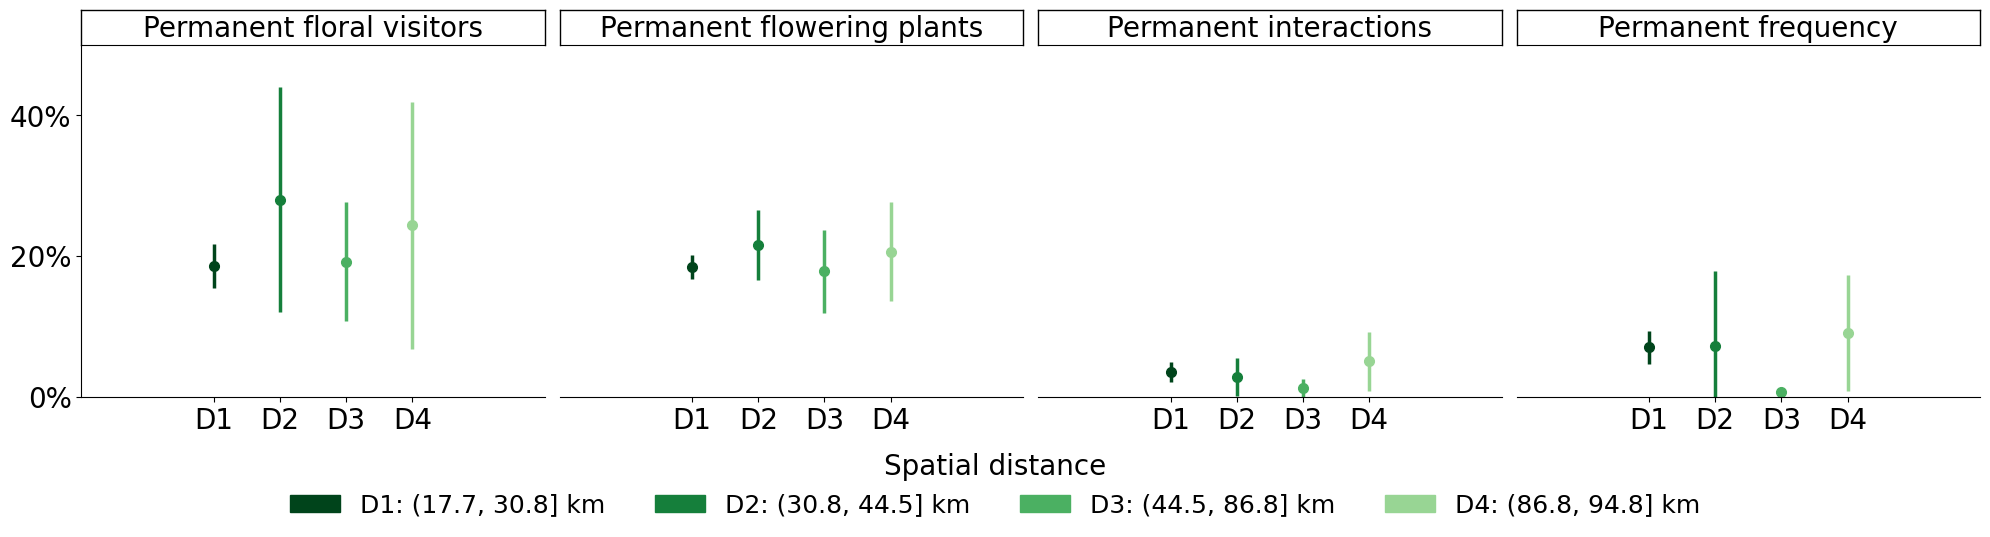

In [17]:
fig, axes, summary_df = plot_persistence_by_distance(Nodes_df, Changes_df,elinewidth=2.5, capsize=0,markersize=14)
for ax in axes:
    ax.set_ylim(0, 0.5)
plt.savefig("distance_diff.png", dpi=150, bbox_inches='tight')

In [18]:
#for all sites 

metric = ['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
metric_N = ["PA", "PP", "A1", "P1", "A2", "P2"]

# todas las parejas posibles de sitios, sin repetir
site_pairs = list(itertools.combinations(sorted(Sites), 2))
comparison_ids = [f"{a}-{b}" for a, b in site_pairs]

Changes_all_df = pd.DataFrame(
    index=pd.MultiIndex.from_product(
        [comparison_ids, metric],
        names=["comparison", "metric"]
    ),
    columns=["n_interactions", "freq_interactions"]
)

Nodes_all_df = pd.DataFrame(
    index=pd.MultiIndex.from_product(
        [comparison_ids, metric_N],
        names=["comparison", "metric"]
    ),
    columns=["n_nodes"]
)

for site_A, site_B in site_pairs:

    comparison = f"{site_A}-{site_B}"

    changes, nodes = rewiring_freq_py(
        networks[site_A],
        networks[site_B]
    )

    changes = changes.set_index("metric")
    nodes = nodes.set_index("metric")

    for m in changes.index:
        Changes_all_df.loc[(comparison, m), "n_interactions"] = changes.loc[m, "n_interactions"]
        Changes_all_df.loc[(comparison, m), "freq_interactions"] = changes.loc[m, "freq_sum"]

    for m in nodes.index:
        Nodes_all_df.loc[(comparison, m), "n_nodes"] = nodes.loc[m, "n_species"]

In [19]:
 #df_dist['bin'], bin_edges = pd.qcut(df_dist['Distance_km'], q=4, labels=['D1', 'D2', 'D3', 'D4'], retbins=True)
#df_dist['bin'] = pd.qcut(df_dist['Distance_km'], q=4, precision=2)
_, bin_edges = pd.qcut(df_dist['Distance_km'], q=4, retbins=True)
bin_edges = np.round(bin_edges, 2)
bin_edges[0] -= 0.01  # para asegurar que el valor minimo quede incluido en el primer bin

df_dist['bin'] = pd.cut(df_dist['Distance_km'], bins=bin_edges, include_lowest=True)
df_dist['comparison'] = df_dist.apply(lambda r: '-'.join(sorted([r['Network_1'], r['Network_2']])), axis=1)
distances_all = df_dist[['comparison', 'Distance_km', 'bin']]

In [20]:
distances_all

,comparison,Distance_km,bin
1,GYL-ROR,3.451314,"(3.439, 16.11]"
2,KAR-STE,4.387153,"(3.439, 16.11]"
3,GYL-KOM,4.591010,"(3.439, 16.11]"
4,SPJ-TOM,5.077535,"(3.439, 16.11]"
5,HAS-KAR,5.183956,"(3.439, 16.11]"
...,...,...,...
149,GYL-TAG,86.777745,"(62.16, 94.78]"
150,ROR-TAG,89.050664,"(62.16, 94.78]"
151,HAM-TAG,91.116054,"(62.16, 94.78]"
152,GLA-TAG,92.886174,"(62.16, 94.78]"


In [21]:
Nodes_all_df = (
    Nodes_all_df
    .reset_index()
    .merge(distances_all, on="comparison", how="left")
    .set_index(["comparison", "Distance_km", "bin", "metric"])
)

Changes_all_df = (
    Changes_all_df
    .reset_index()
    .merge(distances_all, on="comparison", how="left")
    .set_index(["comparison", "Distance_km", "bin", "metric"])
)

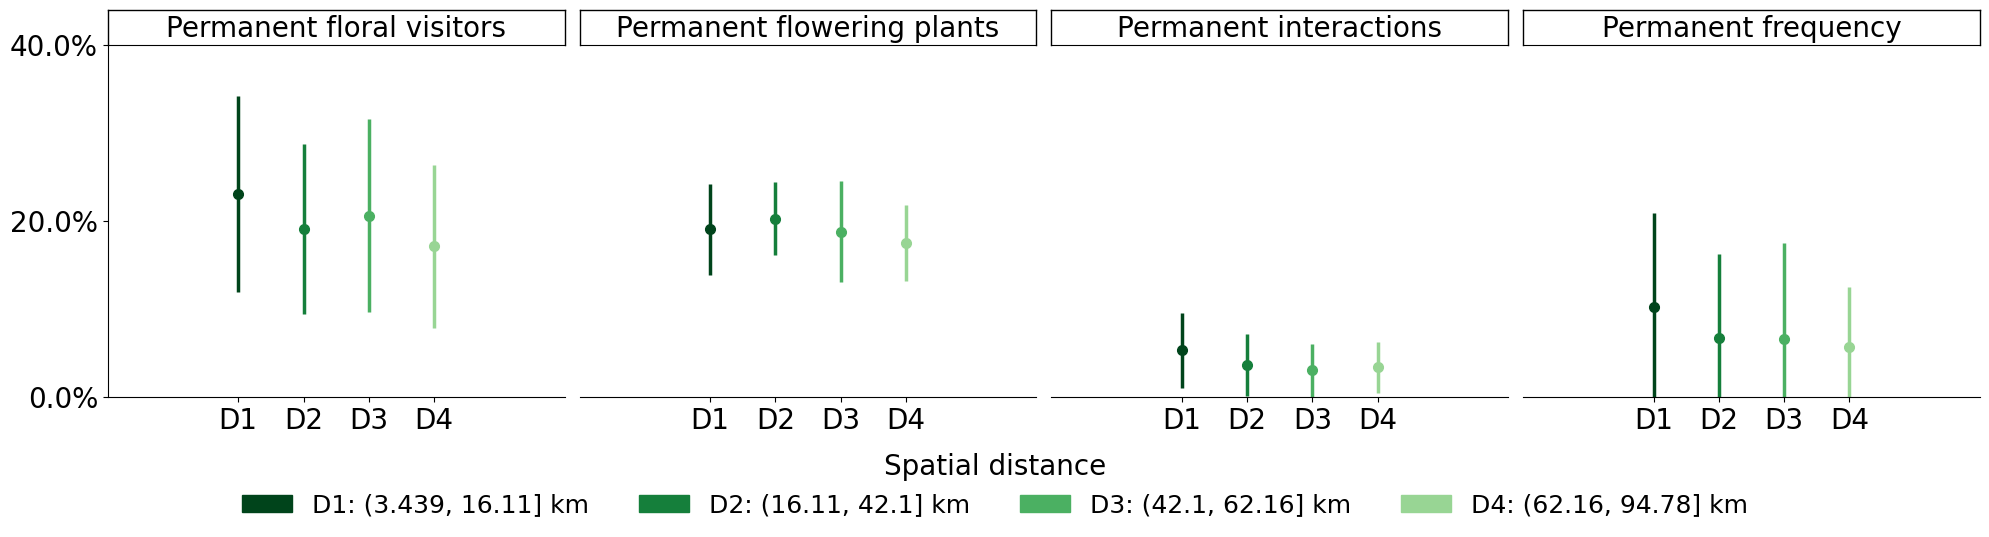

In [22]:
fig, axes, summary_df = plot_persistence_by_distance(Nodes_all_df, Changes_all_df,elinewidth=2.5, capsize=0,markersize=14)
for ax in axes:
    ax.set_ylim(0, 0.4)
plt.savefig("distance_diff_all.png", dpi=150, bbox_inches='tight')

In [23]:
Nodes_all_df.index.get_level_values('bin').unique()

CategoricalIndex([(16.11, 42.1], (62.16, 94.78], (3.439, 16.11],
                  (42.1, 62.16]],
                 categories=[(3.439, 16.11], (16.11, 42.1], (42.1, 62.16], (62.16, 94.78]], ordered=True, dtype='category', name='bin')

# Relationship with space

In [79]:
df3=pd.read_csv(filename3,sep=';', decimal=',', index_col=0)
df3

,id,sitename,Buffer,arable_crops,leys,PGL,forest,water,urban,fruit
1,HAR,Hardeberga,1250,0.640559,0.025265,0.096971,0.049379,0.007557,0.112801,0.000000
2,TAG,Tågarp,1250,0.673735,0.046857,0.148244,0.035900,0.003773,0.046874,0.000530
3,KAG,Kågeröd,1250,0.026543,0.152069,0.160990,0.446313,0.014235,0.021770,0.000000
4,HAS,Hasslebro,1250,0.061745,0.147072,0.211487,0.485405,0.034970,0.047969,0.000509
5,KAR,Kärrstorp,1250,0.252712,0.370701,0.117443,0.188803,0.005155,0.032797,0.000815
...,...,...,...,...,...,...,...,...,...,...
122,PET,Peterslund,750,0.655877,0.080556,0.169864,0.035397,0.015779,0.034567,0.000000
123,HAM,Hammenhög,750,0.779637,0.026325,0.119178,0.009435,0.000000,0.034751,0.000000
124,DAL,Dalby,750,0.013014,0.126795,0.669620,0.092086,0.003001,0.048129,0.000000
125,ASK,Ask-Sonnarp,750,0.494538,0.226376,0.097890,0.128731,0.000906,0.022784,0.000000


In [25]:
Sites2 = list(df1["Network_id"].unique())
pairs = list(itertools.combinations(sorted(Sites2), 2))  # sin repetir, orden alfabetico fijo
comparison_ids = [f"{a}-{b}" for a, b in pairs]

mi_changes = pd.MultiIndex.from_product([comparison_ids, metric], names=["comparison", "metric"])
Spatial_Changes_df = pd.DataFrame(index=mi_changes, columns=["n_interactions", "freq_sum"])

mi_nodes = pd.MultiIndex.from_product([comparison_ids, metric_N], names=["comparison", "metric"])
Spatial_Nodes_df = pd.DataFrame(index=mi_nodes, columns=["n_species"])

for (site_A, site_B), comp_id in zip(pairs, comparison_ids):
    result, node_counts = rewiring_freq_py(networks[site_A], networks[site_B])

    for m in metric:
        row = result.loc[result['metric'] == m]
        Spatial_Changes_df.loc[(comp_id, m), 'n_interactions'] = row['n_interactions'].values[0]
        Spatial_Changes_df.loc[(comp_id, m), 'freq_sum'] = row['freq_sum'].values[0]

    for m in metric_N:
        row = node_counts.loc[node_counts['metric'] == m]
        Spatial_Nodes_df.loc[(comp_id, m), 'n_species'] = row['n_species'].values[0]


Spatial_Changes_df.dropna(inplace=True)
Spatial_Nodes_df.dropna(inplace=True)


Spatial_Changes_df['n_interactions'] = pd.to_numeric(Spatial_Changes_df['n_interactions'], errors='coerce')
Spatial_Changes_df['freq_sum'] = pd.to_numeric(Spatial_Changes_df['freq_sum'], errors='coerce')
Spatial_Nodes_df['n_species'] = pd.to_numeric(Spatial_Nodes_df['n_species'], errors='coerce')

In [26]:
Spatial_Nodes_df

n_species
comparison metric           
ASK-DAL    PA             13
           PP              4
           A1             21
           P1              6
           A2             26
...                      ...
TAG-TOM    PP              4
           A1             26
           P1             13
           A2             45
           P2              8

[918 rows x 1 columns]

In [27]:
#crea una matriz de dsitancias en % arabale entre sitios
from scipy.spatial.distance import pdist, squareform
sites_sorted = sorted(Sites)
#1250   1500   1750  2000    250    500    750     
landuse_cols = ['arable_crops', 'leys', 'PGL', 'forest', 'water', 'urban', 'fruit']
df_1250 = df3[df3['Buffer'] == 2000].set_index('id')[landuse_cols]

arable_dist = pdist(df_1250[['arable_crops']].values, metric='cityblock')
arable_matrix = pd.DataFrame(squareform(arable_dist), index=df_1250.index, columns=df_1250.index)
arable_matrix = arable_matrix.sort_index(axis=0).sort_index(axis=1)
arable_matrix

id,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
id,,,,,,,,,,,,,,,,,,
ASK,0.000000,0.419383,0.066343,0.418575,0.306866,0.206817,0.388806,0.447356,0.189125,0.157062,0.098522,0.164496,0.248741,0.386953,0.097326,0.009787,0.249041,0.152161
DAL,0.419383,0.000000,0.353040,0.000807,0.726249,0.626200,0.030577,0.027973,0.230258,0.262321,0.517905,0.583879,0.668124,0.032429,0.516708,0.429170,0.668423,0.571543
GLA,0.066343,0.353040,0.000000,0.352232,0.373209,0.273160,0.322463,0.381013,0.122782,0.090719,0.164865,0.230839,0.315084,0.320611,0.163669,0.076130,0.315384,0.218504
GYL,0.418575,0.000807,0.352232,0.000000,0.725441,0.625392,0.029770,0.028780,0.229451,0.261514,0.517098,0.583071,0.667317,0.031622,0.515901,0.428363,0.667616,0.570736
HAM,0.306866,0.726249,0.373209,0.725441,0.000000,0.100049,0.695672,0.754222,0.495990,0.463928,0.208343,0.142370,0.058124,0.693819,0.209540,0.297078,0.057825,0.154705
HAR,0.206817,0.626200,0.273160,0.625392,0.100049,0.000000,0.595623,0.654172,0.395941,0.363878,0.108294,0.042321,0.041925,0.593770,0.109491,0.197029,0.042224,0.054656
HAS,0.388806,0.030577,0.322463,0.029770,0.695672,0.595623,0.000000,0.058550,0.199681,0.231744,0.487328,0.553302,0.637547,0.001852,0.486131,0.398593,0.637846,0.540966
KAG,0.447356,0.027973,0.381013,0.028780,0.754222,0.654172,0.058550,0.000000,0.258231,0.290294,0.545878,0.611852,0.696097,0.060402,0.544681,0.457143,0.696396,0.599516
KAR,0.189125,0.230258,0.122782,0.229451,0.495990,0.395941,0.199681,0.258231,0.000000,0.032063,0.287647,0.353621,0.437866,0.197829,0.286450,0.198912,0.438165,0.341285


In [28]:
#crear una matriz de distancias de Bray Curtis del paisaje de cada apr de sitios
from scipy.spatial.distance import pdist, squareform
sites_sorted = sorted(Sites)
#1250   1500   1750  2000    250    500    750     
landuse_cols = ['arable_crops', 'leys', 'PGL', 'forest', 'water', 'urban', 'fruit']

df_1250 = df3[df3['Buffer'] == 2000].set_index('id')[landuse_cols]

bc_dist = pdist(df_1250.values, metric='braycurtis')
bc_matrix = pd.DataFrame(squareform(bc_dist), index=df_1250.index, columns=df_1250.index)
bc_matrix = bc_matrix.sort_index(axis=0).sort_index(axis=1)

In [29]:
bc_matrix

id,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
id,,,,,,,,,,,,,,,,,,
ASK,0.000000,0.492317,0.165653,0.440575,0.339312,0.291168,0.411164,0.472731,0.196503,0.247022,0.135409,0.172557,0.309502,0.400383,0.192061,0.118577,0.303294,0.210958
DAL,0.492317,0.000000,0.475727,0.317227,0.738679,0.667436,0.366765,0.391176,0.415087,0.437178,0.592520,0.605994,0.685964,0.243427,0.606512,0.606843,0.691326,0.617492
GLA,0.165653,0.475727,0.000000,0.424165,0.403696,0.338984,0.421277,0.486446,0.182585,0.089999,0.197316,0.244777,0.339905,0.355895,0.176880,0.126627,0.343418,0.243448
GYL,0.440575,0.317227,0.424165,0.000000,0.751534,0.681213,0.059483,0.113961,0.362403,0.393983,0.563395,0.604883,0.687194,0.217026,0.556169,0.535326,0.693079,0.592216
HAM,0.339312,0.738679,0.403696,0.751534,0.000000,0.090278,0.721910,0.794311,0.517567,0.490058,0.218498,0.178681,0.066251,0.712143,0.226535,0.344344,0.063230,0.163815
HAR,0.291168,0.667436,0.338984,0.681213,0.090278,0.000000,0.651953,0.722921,0.456107,0.426591,0.160629,0.126277,0.057599,0.653551,0.178823,0.283251,0.058260,0.112602
HAS,0.411164,0.366765,0.421277,0.059483,0.721910,0.651953,0.000000,0.117572,0.330081,0.405567,0.536388,0.577952,0.658067,0.234184,0.520951,0.500789,0.663798,0.564620
KAG,0.472731,0.391176,0.486446,0.113961,0.794311,0.722921,0.117572,0.000000,0.402955,0.475149,0.589139,0.632261,0.728451,0.305775,0.603849,0.577721,0.734767,0.631612
KAR,0.196503,0.415087,0.182585,0.362403,0.517567,0.456107,0.330081,0.402955,0.000000,0.115206,0.319768,0.366793,0.456079,0.290523,0.305344,0.227927,0.457334,0.356081


In [30]:
dist_km_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in df_dist.iterrows():
    a, b, d = row['Network_1'], row['Network_2'], row['Distance_km']
    dist_km_matrix.loc[a, b] = d
    dist_km_matrix.loc[b, a] = d

dist_km_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,33.550866,78.501580,72.261262,78.280643,28.894792,11.182565,6.323301,10.716247,71.744938,30.686002,29.125526,80.985837,74.198453,65.352598,15.097824,17.688855,67.978871
DAL,33.550866,NaN,57.393116,51.954311,52.956315,6.437677,30.790614,39.873651,26.098787,49.572202,17.704603,22.763407,57.999608,54.917584,42.104272,24.015315,40.584471,42.637202
GLA,78.501580,57.393116,NaN,6.276967,11.726101,63.354681,68.579832,83.343663,67.791159,7.893037,48.444499,49.385563,5.278300,5.651265,15.400473,63.405399,92.886174,16.669001
GYL,72.261262,51.954311,6.276967,NaN,13.356087,57.780483,62.306717,77.076381,61.554897,4.591010,42.316776,43.138837,10.134132,3.451314,10.806058,57.168163,86.777745,13.716668
HAM,78.280643,52.956315,11.726101,13.356087,NaN,59.267224,69.305070,83.659741,67.652230,9.680345,47.596683,49.819006,7.752718,15.586866,13.206314,63.356422,91.116054,10.495306
HAR,28.894792,6.437677,63.354681,57.780483,59.267224,NaN,28.039034,35.174979,22.986025,55.585406,20.342469,24.539106,64.148394,60.650861,48.162595,21.917410,34.383911,48.899650
HAS,11.182565,30.790614,68.579832,62.306717,69.305070,28.039034,NaN,14.841323,5.183956,62.161996,22.402612,19.492411,71.397597,64.034104,56.175487,7.087957,28.676763,59.255051
KAG,6.323301,39.873651,83.343663,77.076381,83.659741,35.174979,14.841323,NaN,16.094894,76.802726,36.184160,34.047012,86.047739,78.852223,70.621359,20.313107,17.794594,73.453511
KAR,10.716247,26.098787,67.791159,61.554897,67.652230,22.986025,5.183956,16.094894,NaN,61.032239,20.104128,18.431235,70.274353,63.520913,54.678726,4.387153,26.722400,57.398848
KOM,71.744938,49.572202,7.893037,4.591010,9.680345,55.585406,62.161996,76.802726,61.032239,NaN,41.349413,42.755718,9.246033,7.859252,7.511558,56.663272,85.658274,9.363189


In [31]:
# Para ahcer el test de mantel tenemos que convertir cada varibale que nos interese en una amtriz. Así tenemos que convertir la Spatial_changes_df en la matriz de las cosas que nos interesan

Spatial_Nodes_wide = Spatial_Nodes_df.reset_index().pivot_table(
    index='comparison', columns='metric', values='n_species'
)
Spatial_Nodes_wide.columns.name = None
Spatial_Nodes_wide.reset_index(inplace=True)

Spatial_Nodes_wide[['site_A', 'site_B']] = Spatial_Nodes_wide['comparison'].str.split('-', n=1, expand=True)

Spatial_Nodes_wide['poll_permanent_ratio'] = (
    Spatial_Nodes_wide['PA'] / (Spatial_Nodes_wide['PA'] + Spatial_Nodes_wide['A1'] + Spatial_Nodes_wide['A2'])
)

poll_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in Spatial_Nodes_wide.iterrows():
    a, b, v = row['site_A'], row['site_B'], row['poll_permanent_ratio']
    poll_matrix.loc[a, b] = v
    poll_matrix.loc[b, a] = v

poll_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,0.216667,0.206897,0.196078,0.202899,0.163636,0.250000,0.238095,0.290323,0.206897,0.196078,0.237288,0.164384,0.079365,0.186667,0.267857,0.161765,0.180723
DAL,0.216667,NaN,0.229508,0.222222,0.189189,0.210526,0.209677,0.169014,0.250000,0.315789,0.269231,0.278689,0.184211,0.158730,0.205128,0.151515,0.253731,0.256098
GLA,0.206897,0.229508,NaN,0.125000,0.197183,0.200000,0.161290,0.194030,0.205882,0.241379,0.260000,0.190476,0.160000,0.147541,0.151899,0.216667,0.173913,0.204819
GYL,0.196078,0.222222,0.125000,NaN,0.085714,0.187500,0.105263,0.126984,0.140625,0.235294,0.173913,0.222222,0.147059,0.129630,0.188406,0.142857,0.090909,0.137500
HAM,0.202899,0.189189,0.197183,0.085714,NaN,0.179104,0.164384,0.148148,0.172840,0.231884,0.117647,0.275362,0.219512,0.106667,0.195402,0.194444,0.305556,0.228261
HAR,0.163636,0.210526,0.200000,0.187500,0.179104,NaN,0.178571,0.174603,0.206349,0.245283,0.187500,0.301887,0.173913,0.142857,0.214286,0.155172,0.229508,0.175000
HAS,0.250000,0.209677,0.161290,0.105263,0.164384,0.178571,NaN,0.212121,0.281250,0.161290,0.188679,0.190476,0.101266,0.129032,0.109756,0.158730,0.173913,0.176471
KAG,0.238095,0.169014,0.194030,0.126984,0.148148,0.174603,0.212121,NaN,0.200000,0.176471,0.145161,0.220588,0.187500,0.098592,0.151163,0.265625,0.202703,0.200000
KAR,0.290323,0.250000,0.205882,0.140625,0.172840,0.206349,0.281250,0.200000,NaN,0.171429,0.216667,0.250000,0.168675,0.212121,0.216867,0.169014,0.197368,0.250000
KOM,0.206897,0.315789,0.241379,0.235294,0.231884,0.245283,0.161290,0.176471,0.171429,NaN,0.211538,0.229508,0.208333,0.147541,0.229730,0.216667,0.191176,0.234568


In [32]:
#matriz de % plantas permanentes
Spatial_Nodes_wide['plant_permanent_ratio'] = (
    Spatial_Nodes_wide['PP'] / (Spatial_Nodes_wide['PP'] + Spatial_Nodes_wide['P1'] + Spatial_Nodes_wide['P2'])
)

plant_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in Spatial_Nodes_wide.iterrows():
    a, b, v = row['site_A'], row['site_B'], row['plant_permanent_ratio']
    plant_matrix.loc[a, b] = v
    plant_matrix.loc[b, a] = v

plant_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,0.222222,0.187500,0.222222,0.157895,0.117647,0.416667,0.461538,0.333333,0.222222,0.368421,0.190476,0.173913,0.052632,0.187500,0.416667,0.173913,0.294118
DAL,0.222222,NaN,0.166667,0.333333,0.142857,0.166667,0.117647,0.235294,0.222222,0.411765,0.166667,0.173913,0.160000,0.100000,0.235294,0.266667,0.160000,0.411765
GLA,0.187500,0.166667,NaN,0.235294,0.235294,0.200000,0.230769,0.125000,0.266667,0.235294,0.315789,0.263158,0.181818,0.055556,0.125000,0.230769,0.444444,0.166667
GYL,0.222222,0.333333,0.235294,NaN,0.142857,0.105263,0.055556,0.166667,0.157895,0.333333,0.217391,0.350000,0.115385,0.047619,0.312500,0.187500,0.318182,0.200000
HAM,0.157895,0.142857,0.235294,0.142857,NaN,0.166667,0.117647,0.050000,0.157895,0.142857,0.120000,0.173913,0.115385,0.047619,0.166667,0.117647,0.318182,0.263158
HAR,0.117647,0.166667,0.200000,0.105263,0.166667,NaN,0.066667,0.125000,0.266667,0.312500,0.086957,0.090909,0.238095,0.266667,0.058824,0.142857,0.130435,0.235294
HAS,0.416667,0.117647,0.230769,0.055556,0.117647,0.066667,NaN,0.333333,0.307692,0.117647,0.277778,0.100000,0.090909,0.000000,0.142857,0.272727,0.142857,0.187500
KAG,0.461538,0.235294,0.125000,0.166667,0.050000,0.125000,0.333333,NaN,0.187500,0.235294,0.250000,0.142857,0.181818,0.055556,0.285714,0.600000,0.181818,0.235294
KAR,0.333333,0.222222,0.266667,0.157895,0.157895,0.266667,0.307692,0.187500,NaN,0.157895,0.300000,0.190476,0.080000,0.052632,0.055556,0.307692,0.227273,0.294118
KOM,0.222222,0.411765,0.235294,0.333333,0.142857,0.312500,0.117647,0.235294,0.157895,NaN,0.166667,0.227273,0.318182,0.157895,0.312500,0.187500,0.160000,0.411765


In [33]:
# % permanent interactions
Spatial_Changes_n = Spatial_Changes_df.reset_index().pivot_table(
    index='comparison', columns='metric', values='n_interactions'
)
Spatial_Changes_n.columns.name = None
Spatial_Changes_n.reset_index(inplace=True)

Spatial_Changes_n[['site_A', 'site_B']] = Spatial_Changes_n['comparison'].str.split('-', n=1, expand=True)

permanent_cats = ['CN_CI', 'CN_DI', 'CN_II']
all_cats = ['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']

Spatial_Changes_n['permanent_interactions_ratio'] = (
    Spatial_Changes_n[permanent_cats].sum(axis=1) / Spatial_Changes_n[all_cats].sum(axis=1)
)

interactions_n_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in Spatial_Changes_n.iterrows():
    a, b, v = row['site_A'], row['site_B'], row['permanent_interactions_ratio']
    interactions_n_matrix.loc[a, b] = v
    interactions_n_matrix.loc[b, a] = v

interactions_n_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,0.031250,0.011111,0.054795,0.065041,0.036585,0.088608,0.159091,0.120370,0.063158,0.025000,0.044248,0.034783,0.000000,0.025641,0.126437,0.016529,0.084615
DAL,0.031250,NaN,0.000000,0.023810,0.029412,0.010753,0.043956,0.057143,0.065574,0.134021,0.045977,0.016000,0.032258,0.010204,0.040323,0.019048,0.031250,0.079137
GLA,0.011111,0.000000,NaN,0.000000,0.081967,0.036145,0.023529,0.019802,0.025210,0.020000,0.050633,0.053097,0.052632,0.022472,0.016807,0.020619,0.059829,0.021583
GYL,0.054795,0.023810,0.000000,NaN,0.000000,0.000000,0.000000,0.059524,0.009346,0.060241,0.000000,0.009615,0.009524,0.000000,0.049020,0.036585,0.000000,0.024000
HAM,0.065041,0.029412,0.081967,0.000000,NaN,0.032787,0.032520,0.051471,0.051948,0.044118,0.016529,0.067114,0.073826,0.007692,0.052288,0.085938,0.100671,0.089820
HAR,0.036585,0.010753,0.036145,0.000000,0.032787,NaN,0.000000,0.010417,0.054545,0.032258,0.000000,0.018018,0.045872,0.000000,0.000000,0.021978,0.000000,0.038168
HAS,0.088608,0.043956,0.023529,0.000000,0.032520,0.000000,NaN,0.065217,0.114286,0.000000,0.054054,0.008850,0.000000,0.000000,0.000000,0.032967,0.043860,0.053846
KAG,0.159091,0.057143,0.019802,0.059524,0.051471,0.010417,0.065217,NaN,0.099174,0.056075,0.056180,0.040000,0.023438,0.000000,0.031250,0.208791,0.046512,0.100719
KAR,0.120370,0.065574,0.025210,0.009346,0.051948,0.054545,0.114286,0.099174,NaN,0.023256,0.086538,0.049296,0.027397,0.000000,0.006667,0.084034,0.047619,0.088608
KOM,0.063158,0.134021,0.020000,0.060241,0.044118,0.032258,0.000000,0.056075,0.023256,NaN,0.000000,0.023810,0.015625,0.020202,0.073770,0.038095,0.007519,0.142857


In [34]:
# frequency of itneraactions permanent
Spatial_Changes_freq = Spatial_Changes_df.reset_index().pivot_table(
    index='comparison', columns='metric', values='freq_sum'
)
Spatial_Changes_freq.columns.name = None
Spatial_Changes_freq.reset_index(inplace=True)

Spatial_Changes_freq[['site_A', 'site_B']] = Spatial_Changes_freq['comparison'].str.split('-', n=1, expand=True)

Spatial_Changes_freq['permanent_frequency_ratio'] = (
    Spatial_Changes_freq[permanent_cats].sum(axis=1) / Spatial_Changes_freq[all_cats].sum(axis=1)
)

interactions_freq_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in Spatial_Changes_freq.iterrows():
    a, b, v = row['site_A'], row['site_B'], row['permanent_frequency_ratio']
    interactions_freq_matrix.loc[a, b] = v
    interactions_freq_matrix.loc[b, a] = v

interactions_freq_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,0.014337,0.005747,0.027211,0.075758,0.015464,0.178571,0.259067,0.276596,0.043243,0.051613,0.026820,0.018868,0.000000,0.011407,0.309160,0.045685,0.182336
DAL,0.014337,NaN,0.000000,0.008000,0.029018,0.003300,0.028000,0.126100,0.048023,0.540000,0.023438,0.010667,0.015823,0.045283,0.019553,0.154412,0.016340,0.333333
GLA,0.005747,0.000000,NaN,0.000000,0.176471,0.078947,0.027211,0.021277,0.056000,0.021277,0.041379,0.064000,0.118812,0.012579,0.011673,0.009967,0.076087,0.013263
GYL,0.027211,0.008000,0.000000,NaN,0.000000,0.000000,0.000000,0.028169,0.004184,0.031847,0.000000,0.004065,0.005236,0.000000,0.035556,0.025547,0.000000,0.057803
HAM,0.075758,0.029018,0.176471,0.000000,NaN,0.077348,0.031546,0.157068,0.052885,0.033708,0.018868,0.050725,0.168605,0.002985,0.076010,0.215909,0.200581,0.116232
HAR,0.015464,0.003300,0.078947,0.000000,0.077348,NaN,0.000000,0.041199,0.073529,0.080189,0.000000,0.054608,0.057522,0.000000,0.000000,0.177914,0.000000,0.085427
HAS,0.178571,0.028000,0.027211,0.000000,0.031546,0.000000,NaN,0.109524,0.281690,0.000000,0.057851,0.028112,0.000000,0.000000,0.000000,0.039427,0.052023,0.037464
KAG,0.259067,0.126100,0.021277,0.028169,0.157068,0.041199,0.109524,NaN,0.247232,0.133858,0.182243,0.184127,0.132616,0.000000,0.018349,0.543071,0.066929,0.184066
KAR,0.276596,0.048023,0.056000,0.004184,0.052885,0.073529,0.281690,0.247232,NaN,0.050360,0.076923,0.067647,0.033670,0.000000,0.002833,0.266854,0.104693,0.161593
KOM,0.043243,0.540000,0.021277,0.031847,0.033708,0.080189,0.000000,0.133858,0.050360,NaN,0.000000,0.024476,0.012931,0.034286,0.083650,0.234177,0.004484,0.368116


In [35]:
# %rewiring
rewiring_cats = ['CN_LI', 'CN_GI']
turnover_cats = ['L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
all_change_cats = rewiring_cats + turnover_cats

Spatial_Changes_n['rewiring_ratio'] = (
    Spatial_Changes_n[rewiring_cats].sum(axis=1) / Spatial_Changes_n[all_change_cats].sum(axis=1)
)

rewiring_matrix = pd.DataFrame(np.nan, index=sites_sorted, columns=sites_sorted)

for _, row in Spatial_Changes_n.iterrows():
    a, b, v = row['site_A'], row['site_B'], row['rewiring_ratio']
    rewiring_matrix.loc[a, b] = v
    rewiring_matrix.loc[b, a] = v

rewiring_matrix

,ASK,DAL,GLA,GYL,HAM,HAR,HAS,KAG,KAR,KOM,LOB,LYB,PET,ROR,SPJ,STE,TAG,TOM
ASK,NaN,0.172043,0.089888,0.115942,0.034783,0.050633,0.194444,0.229730,0.157895,0.101124,0.205128,0.083333,0.099099,0.011111,0.070175,0.236842,0.075630,0.117647
DAL,0.172043,NaN,0.070000,0.219512,0.075758,0.054348,0.080460,0.131313,0.184211,0.226190,0.120482,0.073171,0.058333,0.082474,0.092437,0.174757,0.096774,0.265625
GLA,0.089888,0.070000,NaN,0.012821,0.187500,0.050000,0.108434,0.121212,0.181034,0.091837,0.186667,0.149533,0.092593,0.011494,0.059829,0.200000,0.136364,0.110294
GYL,0.115942,0.219512,0.012821,NaN,0.050847,0.041667,0.000000,0.113924,0.066038,0.166667,0.101449,0.145631,0.057692,0.025974,0.134021,0.126582,0.045455,0.114754
HAM,0.034783,0.075758,0.187500,0.050847,NaN,0.101695,0.067227,0.023256,0.041096,0.100000,0.075630,0.194245,0.123188,0.023256,0.103448,0.034188,0.291045,0.105263
HAR,0.050633,0.054348,0.050000,0.041667,0.101695,NaN,0.024691,0.126316,0.125000,0.111111,0.064935,0.073394,0.105769,0.152941,0.026087,0.112360,0.067797,0.126984
HAS,0.194444,0.080460,0.108434,0.000000,0.067227,0.024691,NaN,0.104651,0.161290,0.020619,0.185714,0.089286,0.026087,0.000000,0.008621,0.113636,0.082569,0.081301
KAG,0.229730,0.131313,0.121212,0.113924,0.023256,0.126316,0.104651,NaN,0.100917,0.099010,0.107143,0.158333,0.144000,0.000000,0.145161,0.208333,0.130081,0.104000
KAR,0.157895,0.184211,0.181034,0.066038,0.041096,0.125000,0.161290,0.100917,NaN,0.111111,0.168421,0.170370,0.084507,0.024793,0.060403,0.128440,0.128571,0.166667
KOM,0.101124,0.226190,0.091837,0.166667,0.100000,0.111111,0.020619,0.099010,0.111111,NaN,0.086022,0.073171,0.158730,0.072165,0.141593,0.128713,0.053030,0.280702


In [36]:
#este es eltest de mantel
def mantel_test(mat_a, mat_b, n_perm=999, seed=0):
    sites = mat_a.index.tolist()
    mat_b = mat_b.loc[sites, sites]  # mismo orden de sitios

    iu = np.triu_indices(len(sites), k=1)
    vec_a = mat_a.values[iu]
    vec_b = mat_b.values[iu]

    obs_rho, _ = spearmanr(vec_a, vec_b, nan_policy='omit')

    rng = np.random.default_rng(seed)
    idx = np.arange(len(sites))
    perm_rhos = np.empty(n_perm)
    for i in range(n_perm):
        perm_idx = rng.permutation(idx)
        permuted_b = mat_b.values[np.ix_(perm_idx, perm_idx)]
        perm_rhos[i], _ = spearmanr(vec_a, permuted_b[iu], nan_policy='omit')

    p_value = (np.sum(np.abs(perm_rhos) >= np.abs(obs_rho)) + 1) / (n_perm + 1)
    return obs_rho, p_value

In [37]:
network_matrices = {
    'Poll. permanent ratio':        poll_matrix,
    'Plant permanent ratio':        plant_matrix,
    'Permanent interactions (n)':   interactions_n_matrix,
    'Permanent interactions (freq)':interactions_freq_matrix,
    'Rewiring ratio':               rewiring_matrix,
}

distance_matrices = {
    'distance_km':   dist_km_matrix,
    'landscape_arable':  arable_matrix,
}
from scipy.stats import spearmanr
results = []
for var_label, var_matrix in network_matrices.items():
    for dist_label, dist_matrix in distance_matrices.items():
        rho, p = mantel_test(var_matrix, dist_matrix, n_perm=999)
        results.append({'variable': var_label, 'distance_type': dist_label,
                         'mantel_rho': rho, 'p_value': p})


mantel_df = pd.DataFrame(results)

from statsmodels.stats.multitest import multipletests

mantel_df['p_fdr'] = multipletests(mantel_df['p_value'], method='fdr_bh')[1]
mantel_df

,variable,distance_type,mantel_rho,p_value,p_fdr
0,Poll. permanent ratio,distance_km,-0.167703,0.032,0.075000
1,Poll. permanent ratio,landscape_arable,-0.158313,0.045,0.075000
2,Plant permanent ratio,distance_km,-0.192789,0.021,0.075000
3,Plant permanent ratio,landscape_arable,-0.057510,0.470,0.470000
4,Permanent interactions (n),distance_km,-0.172390,0.040,0.075000
5,Permanent interactions (n),landscape_arable,-0.103429,0.228,0.253333
6,Permanent interactions (freq),distance_km,-0.168417,0.038,0.075000
7,Permanent interactions (freq),landscape_arable,-0.127475,0.112,0.140000
8,Rewiring ratio,distance_km,-0.200562,0.013,0.075000
9,Rewiring ratio,landscape_arable,-0.142144,0.061,0.087143


In [38]:
# --- construir la tabla de resultados del test de Mantel para LaTeX ---

# 1. formatear cada celda como "rho (p)" con 2 decimales
mantel_df['cell'] = mantel_df.apply(
    lambda r: f"{r['mantel_rho']:.2f} ({r['p_fdr']:.2f})", axis=1
)

# 2. pivotar: variables en filas, distance_type en columnas
table = mantel_df.pivot(index='variable', columns='distance_type', values='cell')

# 3. renombrar filas y columnas para el manuscrito
row_labels = {
    'Poll. permanent ratio': 'Pollinators (\\% permanent)',
    'Plant permanent ratio': 'Plants (\\% permanent)',
    'Permanent interactions (n)': 'Interactions (\\% permanent, count)',
    'Permanent interactions (freq)': 'Interactions (\\% permanent, frequency)',
    'Rewiring ratio': 'Rewiring (\\%)',
}
col_labels = {
    'distance_km': 'Geographic distance',
    'landscape_arable': 'Landscape',
}

table = table.rename(index=row_labels, columns=col_labels)
table = table.loc[list(row_labels.values()), list(col_labels.values())]  # orden fijo

# 4. exportar a LaTeX
latex_table = table.to_latex(
    index=True,
    escape=False,          # para que el \% no se escape doble
    column_format="lcc",
    caption="Mantel correlation coefficients (Spearman's $\\rho$) and permutation-based $p$-values (in parentheses) between each network persistence metric and geographic distance or landscape dissimilarity (absolute difference in \\% arable crops).",
    label="tab:mantel_results",
)

print(latex_table)

\begin{table}
\centering
\caption{Mantel correlation coefficients (Spearman's $\rho$) and permutation-based $p$-values (in parentheses) between each network persistence metric and geographic distance or landscape dissimilarity (absolute difference in \% arable crops).}
\label{tab:mantel_results}
\begin{tabular}{lcc}
\toprule
distance_type & Geographic distance &     Landscape \\
variable                               &                     &               \\
\midrule
Pollinators (\% permanent)             &        -0.17 (0.07) &  -0.16 (0.07) \\
Plants (\% permanent)                  &        -0.19 (0.07) &  -0.06 (0.47) \\
Interactions (\% permanent, count)     &        -0.17 (0.07) &  -0.10 (0.25) \\
Interactions (\% permanent, frequency) &        -0.17 (0.07) &  -0.13 (0.14) \\
Rewiring (\%)                          &        -0.20 (0.07) &  -0.14 (0.09) \\
\bottomrule
\end{tabular}
\end{table}



/tmp/ipykernel_6346/2702367513.py:28: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  latex_table = table.to_latex(


In [39]:

mantel_df

,variable,distance_type,mantel_rho,p_value,p_fdr,cell
0,Poll. permanent ratio,distance_km,-0.167703,0.032,0.075000,-0.17 (0.07)
1,Poll. permanent ratio,landscape_arable,-0.158313,0.045,0.075000,-0.16 (0.07)
2,Plant permanent ratio,distance_km,-0.192789,0.021,0.075000,-0.19 (0.07)
3,Plant permanent ratio,landscape_arable,-0.057510,0.470,0.470000,-0.06 (0.47)
4,Permanent interactions (n),distance_km,-0.172390,0.040,0.075000,-0.17 (0.07)
5,Permanent interactions (n),landscape_arable,-0.103429,0.228,0.253333,-0.10 (0.25)
6,Permanent interactions (freq),distance_km,-0.168417,0.038,0.075000,-0.17 (0.07)
7,Permanent interactions (freq),landscape_arable,-0.127475,0.112,0.140000,-0.13 (0.14)
8,Rewiring ratio,distance_km,-0.200562,0.013,0.075000,-0.20 (0.07)
9,Rewiring ratio,landscape_arable,-0.142144,0.061,0.087143,-0.14 (0.09)


In [68]:
results_tag, metrics_tag = test_site_distance_correlations(
    Changes_df, Nodes_df, arable_matrix, site='TAG'
)
print(results_tag.round(2))

           distance          metric   n   rho  p_value  significant
0       Distance_km       Poll_perm  17 -0.02     0.95        False
1       Distance_km      Plant_perm  17  0.08     0.75        False
2       Distance_km  Int_perm_count  17 -0.02     0.93        False
3       Distance_km   Int_perm_freq  17 -0.10     0.71        False
4       Distance_km    Rewiring_pct  17  0.02     0.94        False
5  landscape_arable       Poll_perm  17 -0.36     0.15        False
6  landscape_arable      Plant_perm  17 -0.10     0.70        False
7  landscape_arable  Int_perm_count  17 -0.10     0.71        False
8  landscape_arable   Int_perm_freq  17 -0.26     0.31        False
9  landscape_arable    Rewiring_pct  17 -0.32     0.21        False


In [69]:
results_tag

,distance,metric,n,rho,p_value,significant
0,Distance_km,Poll_perm,17,-0.017167,0.947859,False
1,Distance_km,Plant_perm,17,0.083641,0.749610,False
2,Distance_km,Int_perm_count,17,-0.022113,0.932866,False
3,Distance_km,Int_perm_freq,17,-0.095823,0.714485,False
4,Distance_km,Rewiring_pct,17,0.019608,0.940458,False
5,landscape_arable,Poll_perm,17,-0.362968,0.152160,False
6,landscape_arable,Plant_perm,17,-0.102092,0.696615,False
7,landscape_arable,Int_perm_count,17,-0.098280,0.707463,False
8,landscape_arable,Int_perm_freq,17,-0.260443,0.312685,False
9,landscape_arable,Rewiring_pct,17,-0.321078,0.208898,False


In [78]:
latex_table2 = make_latex_table(results_tag)
print(latex_table2)

\begin{table}[h]
\centering
\begin{tabular}{lcc}
\hline
Metric & Geographic distance & Landscape \\
\hline
Pollinators (\% permanent) & -0.02 (0.95) & -0.36 (0.15) \\
Plants (\% permanent) & 0.08 (0.75) & -0.10 (0.70) \\
Interactions (\% permanent, count) & -0.02 (0.93) & -0.10 (0.71) \\
Interactions (\% permanent, frequency) & -0.10 (0.71) & -0.26 (0.31) \\
Rewiring (\%) & 0.02 (0.94) & -0.32 (0.21) \\
\hline
\end{tabular}
\caption{Spearman correlations ($\rho$, with $p$-values in parentheses) between each network permanence metric and geographic distance or landscape dissimilarity, for site TAG compared against all other sites.}
\label{tab_TAG_correlations}
\end{table}


In [74]:
#ahora tenemos que ahcerlo apra un sitio solos

def test_site_distance_correlations(changes_df, node_df, landscape_matrix, site,
                                     geo_distance_col='Distance_km',
                                     alpha=0.05):
    """
    Reconstruye las 5 metricas de permanencia por comparacion a partir de
    Changes_df y Node_df (que ya contienen solo las comparaciones de un
    sitio focal frente a los demas), añade la distancia de paisaje a partir
    de una matriz de distancias completa, y correlaciona (Spearman) cada
    metrica contra la distancia geografica y contra la de paisaje.

    Parameters
    ----------
    changes_df, node_df : pd.DataFrame
        Como antes, ya filtradas a las comparaciones de 'site'.
    landscape_matrix : pd.DataFrame
        Matriz cuadrada sitio x sitio (p.ej. arable_matrix), con todos los
        sitios en index y columns.
    site : str
        Nombre del sitio focal tal como aparece en landscape_matrix y como
        prefijo en 'comparison' (p.ej. 'TAG', para comparaciones 'TAG-ASK').
    geo_distance_col : str
        Columna de distancia geografica ya presente en changes_df.
    """
    # vector de distancias de paisaje desde 'site' a cada otro sitio,
    # renombrando el indice para que coincida con las etiquetas de 'comparison'
    landscape_vec = landscape_matrix.loc[site].drop(site)
    landscape_vec.index = [f"{site}-{other}" for other in landscape_vec.index]
    landscape_vec.name = 'landscape_arable'

    ch = changes_df.reset_index()
    nd = node_df.reset_index()

    metric_rows = []
    for comparison, group in ch.groupby('comparison'):
        geo_distance = group[geo_distance_col].iloc[0]
        vals = group.set_index('metric')

        total_n = vals['n_interactions'].sum()
        total_freq = vals['freq_interactions'].sum()

        perm_n = vals.loc[['CN_CI', 'CN_DI', 'CN_II'], 'n_interactions'].sum()
        perm_freq = vals.loc[['CN_CI', 'CN_DI', 'CN_II'], 'freq_interactions'].sum()

        rewiring_n = vals.loc[['CN_LI', 'CN_GI'], 'n_interactions'].sum()
        changed_n = vals.loc[
            ['CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI'],
            'n_interactions'
        ].sum()

        node_vals = nd.loc[nd['comparison'] == comparison].set_index('metric')['n_nodes']

        metric_rows.append({
            'comparison': comparison,
            geo_distance_col: geo_distance,
            'landscape_arable': landscape_vec.get(comparison, float('nan')),
            'Poll_perm': node_vals['PA'] / (node_vals['PA'] + node_vals['A1'] + node_vals['A2']),
            'Plant_perm': node_vals['PP'] / (node_vals['PP'] + node_vals['P1'] + node_vals['P2']),
            'Int_perm_count': perm_n / total_n,
            'Int_perm_freq': perm_freq / total_freq,
            'Rewiring_pct': rewiring_n / changed_n if changed_n > 0 else float('nan'),
        })

    metrics_df = pd.DataFrame(metric_rows)

    distance_cols = (geo_distance_col, 'landscape_arable')
    metric_cols = ('Poll_perm', 'Plant_perm', 'Int_perm_count', 'Int_perm_freq', 'Rewiring_pct')
    result_rows = []
    for distance_col in distance_cols:
        for metric_col in metric_cols:
            valid = metrics_df[[distance_col, metric_col]].dropna()
            rho, p_value = spearmanr(valid[distance_col], valid[metric_col])
            result_rows.append({
                'distance': distance_col,
                'metric': metric_col,
                'n': len(valid),
                'rho': rho,
                'p_value': p_value,
                'Rewiring_pct': p_value < alpha
            })

    return pd.DataFrame(result_rows), metrics_df

In [77]:
def make_latex_table(results_df):
    metric_labels = {
    'Poll_perm': 'Pollinators (\\% permanent)',
    'Plant_perm': 'Plants (\\% permanent)',
    'Int_perm_count': 'Interactions (\\% permanent, count)',
    'Int_perm_freq': 'Interactions (\\% permanent, frequency)',
    'Rewiring_pct': 'Rewiring (\\%)',
    }
    distance_labels = {
        'Distance_km': 'Geographic distance',
        'landscape_arable': 'Landscape',
    }
    metric_order = ['Poll_perm', 'Plant_perm', 'Int_perm_count', 'Int_perm_freq', 'Rewiring_pct']
    distance_order = ['Distance_km', 'landscape_arable']

    table = results_df.copy()
    table['formatted'] = table.apply(
        lambda row: f"{row['rho']:.2f} ({row['p_value']:.2f})", axis=1
    )
    pivot = table.pivot(index='metric', columns='distance', values='formatted')
    pivot = pivot.loc[metric_order, distance_order]
    pivot.index = [metric_labels[m] for m in pivot.index]
    pivot.columns = [distance_labels[d] for d in pivot.columns]

    lines = [
        r'\begin{table}[h]',
        r'\centering',
        r'\begin{tabular}{l' + 'c' * len(pivot.columns) + '}',
        r'\hline',
        'Metric & ' + ' & '.join(pivot.columns) + r' \\',
        r'\hline',
    ]
    for idx, row in pivot.iterrows():
        lines.append(f"{idx} & " + ' & '.join(row.values) + r' \\')
    lines += [
        r'\hline',
        r'\end{tabular}',
        r'\caption{Spearman correlations ($\rho$, with $p$-values in parentheses) '
        r'between each network permanence metric and geographic distance or '
        r'landscape dissimilarity, for site TAG compared against all other sites.}',
        r'\label{tab_TAG_correlations}',
        r'\end{table}',
    ]
    return '\n'.join(lines)

    print(make_latex_table(results_tag))

In [40]:
combined_dist = (
    Spatial_Nodes_wide[['comparison', 'distance_km', 'poll_permanent_ratio', 'plant_permanent_ratio']]
    .merge(Spatial_Changes_n[['comparison', 'permanent_interactions_ratio']], on='comparison')
    .merge(Spatial_Changes_freq[['comparison', 'permanent_frequency_ratio']], on='comparison')
)

KeyError: "['distance_km'] not in index"

In [ ]:
print(Spatial_Nodes_wide.columns.tolist())

['comparison', 'A1', 'A2', 'P1', 'P2', 'PA', 'PP', 'site_A', 'site_B', 'poll_permanent_ratio', 'plant_permanent_ratio']


In [ ]:
#construimos database con comapracione entre redes y paisaje
# Pivot para n_interactions: metric -> columnas
Spatial_Changes_n = Spatial_Changes_df.reset_index().pivot_table(
    index='comparison', columns='metric', values='n_interactions'
)

# Pivot para freq_sum: metric -> columnas
Spatial_Changes_freq = Spatial_Changes_df.reset_index().pivot_table(
    index='comparison', columns='metric', values='freq_sum'
)

# Recuperar site_A / site_B en ambos, a partir de "comparison"
for df_ in (Spatial_Changes_n, Spatial_Changes_freq):
    df_.reset_index(inplace=True)
    df_.columns.name = None
    df_[['site_A', 'site_B']] = df_['comparison'].str.split('-', n=1, expand=True)


#include distance ---------
dist_lookup = {
    tuple(sorted([row['Network_1'], row['Network_2']])): row['Distance_km']
    for _, row in df_dist.iterrows()
}

Spatial_Changes_n['distance_km'] = [
    dist_lookup[tuple(sorted([a, b]))]
    for a, b in zip(Spatial_Changes_n['site_A'], Spatial_Changes_n['site_B'])
]
Spatial_Changes_freq['distance_km'] = [
    dist_lookup[tuple(sorted([a, b]))]
    for a, b in zip(Spatial_Changes_n['site_A'], Spatial_Changes_n['site_B'])
]

#include landscape similarity ------
bc_matrix_named = bc_matrix.copy()
bc_matrix_named.index.name = 'site_A'
bc_matrix_named.columns.name = 'site_B'

bc_long = bc_matrix_named.stack().reset_index()
bc_long.columns = ['site_A', 'site_B', 'landscape_bc']

# Merge directo, sin necesidad de duplicar nada
Spatial_Changes_n = Spatial_Changes_n.merge(bc_long, on=['site_A', 'site_B'], how='left')
Spatial_Changes_freq = Spatial_Changes_freq.merge(bc_long, on=['site_A', 'site_B'], how='left')

rewiring_cats = ['CN_LI', 'CN_GI']
turnover_cats = ['L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
all_change_cats = rewiring_cats + turnover_cats


Spatial_Changes_n

,comparison,CN_CI,CN_DI,CN_GI,CN_II,CN_LI,G1N_GI,GBN_GI,L1N_LI,LBN_LI,site_A,site_B,distance_km,landscape_bc
0,ASK-DAL,1,1,4,1,12,25,22,24,6,ASK,DAL,33.550866,0.492317
1,ASK-GLA,0,0,1,1,7,18,26,25,12,ASK,GLA,78.501580,0.165653
2,ASK-GYL,2,1,3,1,5,11,14,27,9,ASK,GYL,72.261262,0.440575
3,ASK-HAM,1,4,3,3,1,38,37,25,11,ASK,HAM,78.280643,0.339312
4,ASK-HAR,0,1,0,2,4,19,18,27,11,ASK,HAR,28.894792,0.291168
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148,SPJ-TAG,0,1,9,1,9,39,28,29,35,SPJ,TAG,78.748098,0.166749
149,SPJ-TOM,3,3,16,5,7,56,13,45,12,SPJ,TOM,5.077535,0.072004
150,STE-TAG,0,2,3,1,13,37,35,36,1,STE,TAG,30.826916,0.308394
151,STE-TOM,3,5,6,2,9,50,30,27,7,STE,TOM,53.140652,0.216144


In [ ]:
#construimos database con comparacion entre especies y paisaje
Spatial_Nodes_wide = Spatial_Nodes_df.reset_index().pivot_table(
    index='comparison', columns='metric', values='n_species'
)
Spatial_Nodes_wide.reset_index(inplace=True)
Spatial_Nodes_wide.columns.name = None

# Recuperar site_A / site_B
Spatial_Nodes_wide[['site_A', 'site_B']] = Spatial_Nodes_wide['comparison'].str.split('-', n=1, expand=True)

#spatial distance
Spatial_Nodes_wide['distance_km'] = [
    dist_lookup[tuple(sorted([a, b]))]
    for a, b in zip(Spatial_Nodes_wide['site_A'], Spatial_Nodes_wide['site_B'])
]

# Distancia de paisaje (Bray-Curtis)
Spatial_Nodes_wide = Spatial_Nodes_wide.merge(bc_long, on=['site_A', 'site_B'], how='left')

Spatial_Nodes_wide

,comparison,A1,A2,P1,P2,PA,PP,site_A,site_B,distance_km,landscape_bc
0,ASK-DAL,21,26,6,8,13,4,ASK,DAL,33.550866,0.492317
1,ASK-GLA,22,24,7,6,12,3,ASK,GLA,78.501580,0.165653
2,ASK-GYL,24,17,6,8,10,4,ASK,GYL,72.261262,0.440575
3,ASK-HAM,20,35,7,9,14,3,ASK,HAM,78.280643,0.339312
4,ASK-HAR,25,21,8,7,9,2,ASK,HAR,28.894792,0.291168
...,...,...,...,...,...,...,...,...,...,...,...
148,SPJ-TAG,37,27,6,14,18,3,SPJ,TAG,78.748098,0.166749
149,SPJ-TOM,36,45,5,8,19,4,SPJ,TOM,5.077535,0.072004
150,STE-TAG,24,32,3,13,13,4,STE,TAG,30.826916,0.308394
151,STE-TOM,21,48,3,8,16,4,STE,TOM,53.140652,0.216144


In [ ]:
#ahora vamos a computar las metricas que hemos estado usando, por ejemplo.
# --- Spatial_Nodes_wide: pollinators y plants permanentes ---
Spatial_Nodes_wide['poll_permanent_ratio'] = (
    Spatial_Nodes_wide['PA'] / (Spatial_Nodes_wide['PA'] + Spatial_Nodes_wide['A1'] + Spatial_Nodes_wide['A2'])
)
Spatial_Nodes_wide['plant_permanent_ratio'] = (
    Spatial_Nodes_wide['PP'] / (Spatial_Nodes_wide['PP'] + Spatial_Nodes_wide['P1'] + Spatial_Nodes_wide['P2'])
)

# --- categorias comunes para las interacciones ---
permanent_cats = ['CN_CI', 'CN_DI', 'CN_II']
all_cats = ['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']

# --- Spatial_Changes_n: interacciones permanentes (conteo) ---
Spatial_Changes_n['permanent_interactions_ratio'] = (
    Spatial_Changes_n[permanent_cats].sum(axis=1) / Spatial_Changes_n[all_cats].sum(axis=1)
)

# --- Spatial_Changes_freq: interacciones permanentes (frecuencia) ---
Spatial_Changes_freq['permanent_frequency_ratio'] = (
    Spatial_Changes_freq[permanent_cats].sum(axis=1) / Spatial_Changes_freq[all_cats].sum(axis=1)
)


#include %of rewiring, sp turnover
for df_ in (Spatial_Changes_n, Spatial_Changes_freq):
    df_['rewiring_ratio'] = df_[rewiring_cats].sum(axis=1) / df_[all_change_cats].sum(axis=1)
    df_['turnover_ratio'] = df_[turnover_cats].sum(axis=1) / df_[all_change_cats].sum(axis=1)

In [ ]:
Spatial_Nodes_wide.loc[:,["poll_permanent_ratio",	"plant_permanent_ratio"]]

,poll_permanent_ratio,plant_permanent_ratio
0,0.216667,0.222222
1,0.206897,0.187500
2,0.196078,0.222222
3,0.202899,0.157895
4,0.163636,0.117647
...,...,...
148,0.219512,0.130435
149,0.190000,0.235294
150,0.188406,0.200000
151,0.188235,0.266667


In [ ]:
Spatial_Changes_n

,comparison,CN_CI,CN_DI,CN_GI,CN_II,CN_LI,G1N_GI,GBN_GI,L1N_LI,LBN_LI,site_A,site_B,distance_km,landscape_bc,permanent_interactions_ratio,rewiring_ratio,turnover_ratio
0,ASK-DAL,1,1,4,1,12,25,22,24,6,ASK,DAL,33.550866,0.492317,0.031250,0.172043,0.827957
1,ASK-GLA,0,0,1,1,7,18,26,25,12,ASK,GLA,78.501580,0.165653,0.011111,0.089888,0.910112
2,ASK-GYL,2,1,3,1,5,11,14,27,9,ASK,GYL,72.261262,0.440575,0.054795,0.115942,0.884058
3,ASK-HAM,1,4,3,3,1,38,37,25,11,ASK,HAM,78.280643,0.339312,0.065041,0.034783,0.965217
4,ASK-HAR,0,1,0,2,4,19,18,27,11,ASK,HAR,28.894792,0.291168,0.036585,0.050633,0.949367
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148,SPJ-TAG,0,1,9,1,9,39,28,29,35,SPJ,TAG,78.748098,0.166749,0.013245,0.120805,0.879195
149,SPJ-TOM,3,3,16,5,7,56,13,45,12,SPJ,TOM,5.077535,0.072004,0.068750,0.154362,0.845638
150,STE-TAG,0,2,3,1,13,37,35,36,1,STE,TAG,30.826916,0.308394,0.023438,0.128000,0.872000
151,STE-TOM,3,5,6,2,9,50,30,27,7,STE,TOM,53.140652,0.216144,0.071942,0.116279,0.883721


In [ ]:
from scipy.stats import spearmanr

variables = {
    'Poll. permanent ratio':       (Spatial_Nodes_wide,   'poll_permanent_ratio'),
    'Plant permanent ratio':       (Spatial_Nodes_wide,   'plant_permanent_ratio'),
    'Permanent interactions (n)':  (Spatial_Changes_n,    'permanent_interactions_ratio'),
    'Permanent interactions (freq)': (Spatial_Changes_freq, 'permanent_frequency_ratio'),
    'rewiring % (n)': (Spatial_Changes_n, 'rewiring_ratio' )
}

results = []
for label, (df_, col) in variables.items():
    for dist_col in ['distance_km', 'landscape_bc']:
        sub = df_[[col, dist_col]].dropna()
        rho, p = spearmanr(sub[col], sub[dist_col])
        results.append({'variable': label, 'distance_type': dist_col,
                         'rho': rho, 'p_value': p, 'n': len(sub)})

corr_df = pd.DataFrame(results)
corr_df

,variable,distance_type,rho,p_value,n
0,Poll. permanent ratio,distance_km,-0.167703,0.038261,153
1,Poll. permanent ratio,landscape_bc,-0.201583,0.012465,153
2,Plant permanent ratio,distance_km,-0.192789,0.016961,153
3,Plant permanent ratio,landscape_bc,-0.086225,0.289246,153
4,Permanent interactions (n),distance_km,-0.172390,0.033103,153
5,Permanent interactions (n),landscape_bc,-0.135207,0.095640,153
6,Permanent interactions (freq),distance_km,-0.168417,0.037434,153
7,Permanent interactions (freq),landscape_bc,-0.162337,0.044979,153
8,rewiring % (n),distance_km,-0.200562,0.012927,153
9,rewiring % (n),landscape_bc,-0.164210,0.042530,153


In [ ]:
combined = (
    Spatial_Nodes_wide[['comparison', 'poll_permanent_ratio', 'plant_permanent_ratio']]
    .merge(Spatial_Changes_n[['comparison', 'permanent_interactions_ratio','rewiring_ratio']], on='comparison')
    .merge(Spatial_Changes_freq[['comparison', 'permanent_frequency_ratio']], on='comparison')
)

vars_ = ['poll_permanent_ratio', 'plant_permanent_ratio',
         'permanent_interactions_ratio', 'permanent_frequency_ratio','rewiring_ratio']

corr_matrix = combined[vars_].corr(method='spearman')
corr_matrix

,poll_permanent_ratio,plant_permanent_ratio,permanent_interactions_ratio,permanent_frequency_ratio,rewiring_ratio
poll_permanent_ratio,1.000000,0.391301,0.489556,0.400345,0.530393
plant_permanent_ratio,0.391301,1.000000,0.611044,0.542234,0.780555
permanent_interactions_ratio,0.489556,0.611044,1.000000,0.857619,0.632960
permanent_frequency_ratio,0.400345,0.542234,0.857619,1.000000,0.643779
rewiring_ratio,0.530393,0.780555,0.632960,0.643779,1.000000


In [ ]:
combined[vars_].corr()

,poll_permanent_ratio,plant_permanent_ratio,permanent_interactions_ratio,permanent_frequency_ratio,rewiring_ratio
poll_permanent_ratio,1.000000,0.443211,0.537480,0.443556,0.583100
plant_permanent_ratio,0.443211,1.000000,0.677398,0.579843,0.788874
permanent_interactions_ratio,0.537480,0.677398,1.000000,0.838478,0.622520
permanent_frequency_ratio,0.443556,0.579843,0.838478,1.000000,0.564139
rewiring_ratio,0.583100,0.788874,0.622520,0.564139,1.000000


In [ ]:
landuse_cols = ['arable_crops', 'leys', 'PGL', 'forest', 'water', 'urban', 'fruit']
sites = df_1250.index.tolist()

diff_records = []
for site_A, site_B in itertools.combinations(sites, 2):
    row = {'site_A': site_A, 'site_B': site_B}
    for col in landuse_cols:
        row[f'diff_{col}'] = abs(df_1250.loc[site_A, col] - df_1250.loc[site_B, col])
    diff_records.append(row)

landscape_diff_df = pd.DataFrame(diff_records)

# Version simetrica (A-B y B-A), igual que hicimos con df_dist_sym, para poder
# mergear sin preocuparte del orden de site_A/site_B en tus otras tablas
landscape_diff_sym = pd.concat([
    landscape_diff_df,
    landscape_diff_df.rename(columns={'site_A': 'site_B', 'site_B': 'site_A'})
], ignore_index=True)

In [ ]:
Spatial_Nodes_wide = Spatial_Nodes_wide.merge(landscape_diff_sym, on=['site_A', 'site_B'], how='left')
Spatial_Changes_n = Spatial_Changes_n.merge(landscape_diff_sym, on=['site_A', 'site_B'], how='left')
Spatial_Changes_freq = Spatial_Changes_freq.merge(landscape_diff_sym, on=['site_A', 'site_B'], how='left')

In [ ]:
Spatial_Nodes_wide.corr(numeric_only=True)

,A1,A2,P1,P2,PA,PP,distance_km,landscape_bc,poll_permanent_ratio,plant_permanent_ratio,...,diff_water_x,diff_urban_x,diff_fruit_x,diff_arable_crops_y,diff_leys_y,diff_PGL_y,diff_forest_y,diff_water_y,diff_urban_y,diff_fruit_y
A1,1.000000,-0.266289,0.186962,0.031525,-0.045144,-0.218758,0.154186,0.083239,-0.265555,-0.229210,...,-0.100797,-0.036044,0.202781,0.080331,0.126941,0.001026,0.036554,-0.100797,-0.036044,0.202781
A2,-0.266289,1.000000,0.089180,0.042637,0.189789,-0.028427,0.036441,-0.017235,-0.278542,-0.070351,...,-0.052604,-0.180053,-0.038002,0.048454,-0.057607,-0.188998,0.072523,-0.052604,-0.180053,-0.038002
P1,0.186962,0.089180,1.000000,-0.048588,-0.181017,-0.455748,0.049824,-0.080102,-0.299708,-0.593829,...,-0.198890,0.072615,0.309227,-0.077158,-0.024045,0.142931,-0.197972,-0.198890,0.072615,0.309227
P2,0.031525,0.042637,-0.048588,1.000000,-0.019946,-0.135467,0.161381,0.077684,-0.051484,-0.430943,...,-0.117698,-0.083784,0.048470,0.154376,0.056544,-0.080287,0.026532,-0.117698,-0.083784,0.048470
PA,-0.045144,0.189789,-0.181017,-0.019946,1.000000,0.350710,-0.082500,-0.226914,0.812101,0.340764,...,-0.310740,0.116260,-0.456251,-0.168480,0.089631,-0.101875,-0.258282,-0.310740,0.116260,-0.456251
PP,-0.218758,-0.028427,-0.455748,-0.135467,0.350710,1.000000,-0.117425,-0.121947,0.420585,0.884985,...,-0.146704,0.028128,-0.414961,-0.075665,0.032800,-0.062467,-0.124678,-0.146704,0.028128,-0.414961
distance_km,0.154186,0.036441,0.049824,0.161381,-0.082500,-0.117425,1.000000,0.012615,-0.163319,-0.183304,...,-0.038825,-0.018876,0.009167,-0.010722,-0.009729,-0.012435,0.063663,-0.038825,-0.018876,0.009167
landscape_bc,0.083239,-0.017235,-0.080102,0.077684,-0.226914,-0.121947,0.012615,1.000000,-0.215274,-0.076429,...,0.276918,0.282724,0.159538,0.956398,0.204340,0.478541,0.807459,0.276918,0.282724,0.159538
poll_permanent_ratio,-0.265555,-0.278542,-0.299708,-0.051484,0.812101,0.420585,-0.163319,-0.215274,1.000000,0.443211,...,-0.205462,0.226132,-0.479450,-0.197799,0.064527,0.017018,-0.275636,-0.205462,0.226132,-0.479450
plant_permanent_ratio,-0.229210,-0.070351,-0.593829,-0.430943,0.340764,0.884985,-0.183304,-0.076429,0.443211,1.000000,...,-0.012015,0.019049,-0.395561,-0.069803,0.001761,-0.054118,-0.024233,-0.012015,0.019049,-0.395561


In [ ]:
Spatial_Changes_n.corr(numeric_only=True)

,CN_CI,CN_DI,CN_GI,CN_II,CN_LI,G1N_GI,GBN_GI,L1N_LI,LBN_LI,distance_km,...,permanent_interactions_ratio,rewiring_ratio,turnover_ratio,diff_arable_crops,diff_leys,diff_PGL,diff_forest,diff_water,diff_urban,diff_fruit
CN_CI,1.000000,0.474308,0.379437,0.488759,0.302143,0.339948,-0.260052,0.209793,-0.279572,-0.113031,...,0.742964,0.461050,-0.461050,-0.013067,0.092553,-0.027122,-0.036080,-0.144496,0.059323,-0.239818
CN_DI,0.474308,1.000000,0.167780,0.459087,0.678506,0.353200,-0.145806,0.403637,-0.379674,-0.000017,...,0.736374,0.504134,-0.504134,-0.108986,0.017501,-0.280233,-0.042064,-0.126658,-0.112910,-0.276979
CN_GI,0.379437,0.167780,1.000000,0.538701,0.130940,0.607808,-0.438853,-0.011736,-0.172558,-0.219161,...,0.414500,0.700810,-0.700810,-0.180580,0.053907,0.002299,-0.246507,-0.082101,0.084326,-0.362123
CN_II,0.488759,0.459087,0.538701,1.000000,0.190094,0.459150,-0.430951,0.220020,-0.143781,-0.263552,...,0.819887,0.473640,-0.473640,-0.113456,0.090013,-0.087669,-0.124886,-0.126723,0.019727,-0.289226
CN_LI,0.302143,0.678506,0.130940,0.190094,1.000000,0.245025,-0.139688,0.506084,-0.434085,0.024524,...,0.404337,0.680912,-0.680912,-0.104846,-0.004853,-0.152072,-0.110657,-0.257259,-0.008975,-0.275801
G1N_GI,0.339948,0.353200,0.607808,0.459150,0.245025,1.000000,-0.132536,0.137376,-0.247786,-0.039338,...,0.353231,0.391580,-0.391580,-0.100872,0.059531,-0.179102,-0.144235,-0.151951,-0.017746,-0.500687
GBN_GI,-0.260052,-0.145806,-0.438853,-0.430951,-0.139688,-0.132536,1.000000,-0.019529,-0.000075,0.164967,...,-0.447170,-0.554358,0.554358,0.193005,0.004945,-0.064940,0.135577,-0.072632,-0.182953,0.300945
L1N_LI,0.209793,0.403637,-0.011736,0.220020,0.506084,0.137376,-0.019529,1.000000,-0.002265,0.042834,...,0.234173,0.167909,-0.167909,-0.097154,0.207801,-0.191474,-0.182349,-0.344768,-0.030797,-0.289899
LBN_LI,-0.279572,-0.379674,-0.172558,-0.143781,-0.434085,-0.247786,-0.000075,-0.002265,1.000000,0.121426,...,-0.389991,-0.520010,0.520010,0.051481,0.116483,0.167672,-0.110905,-0.061528,0.023472,0.413377
distance_km,-0.113031,-0.000017,-0.219161,-0.263552,0.024524,-0.039338,0.164967,0.042834,0.121426,1.000000,...,-0.201564,-0.187102,0.187102,-0.010722,-0.009729,-0.012435,0.063663,-0.038825,-0.018876,0.009167


In [ ]:
Spatial_Changes_freq.corr(numeric_only=True)

,CN_CI,CN_DI,CN_GI,CN_II,CN_LI,G1N_GI,GBN_GI,L1N_LI,LBN_LI,distance_km,landscape_bc,permanent_frequency_ratio,diff_arable_crops,diff_leys,diff_PGL,diff_forest,diff_water,diff_urban,diff_fruit
CN_CI,1.000000,0.382852,0.189575,0.326303,0.081905,0.168096,-0.186074,0.091361,-0.048199,-0.085943,-0.016632,0.498667,-0.003049,0.130277,-0.039105,-0.044266,-0.083399,0.063925,-0.223720
CN_DI,0.382852,1.000000,-0.045816,0.159028,0.381193,0.127216,-0.048767,-0.042519,-0.257115,0.053996,-0.000532,0.681159,-0.003539,-0.004383,-0.036330,0.025079,-0.151016,0.119227,-0.162414
CN_GI,0.189575,-0.045816,1.000000,0.383894,-0.133954,0.431137,-0.243812,-0.143062,-0.043285,-0.191017,-0.191219,0.218094,-0.180423,-0.043899,-0.086118,-0.139234,0.030653,-0.043113,-0.257687
CN_II,0.326303,0.159028,0.383894,1.000000,-0.070637,0.158156,-0.226654,0.108285,-0.011061,-0.208865,-0.101284,0.767912,-0.105730,0.116649,-0.058501,-0.107185,-0.040892,0.009684,-0.208602
CN_LI,0.081905,0.381193,-0.133954,-0.070637,1.000000,-0.050821,-0.067844,0.123129,-0.232463,0.034647,-0.112828,0.156152,-0.115998,0.000272,-0.127302,-0.045743,-0.119203,0.034137,-0.169177
G1N_GI,0.168096,0.127216,0.431137,0.158156,-0.050821,1.000000,0.185601,0.069921,-0.153097,-0.058597,-0.120267,0.076332,-0.053786,-0.019181,0.022198,-0.176565,-0.188085,0.079791,-0.351892
GBN_GI,-0.186074,-0.048767,-0.243812,-0.226654,-0.067844,0.185601,1.000000,-0.137257,-0.087398,0.129913,0.116232,-0.275154,0.166430,-0.065802,-0.086182,0.160882,0.009885,-0.174415,0.206628
L1N_LI,0.091361,-0.042519,-0.143062,0.108285,0.123129,0.069921,-0.137257,1.000000,0.226667,-0.013233,0.066236,-0.027705,0.060833,0.194226,0.288388,-0.177658,-0.350815,0.466259,-0.166796
LBN_LI,-0.048199,-0.257115,-0.043285,-0.011061,-0.232463,-0.153097,-0.087398,0.226667,1.000000,0.122004,0.076895,-0.236416,0.054590,0.128526,0.157662,-0.061291,0.000073,0.067882,0.307475
distance_km,-0.085943,0.053996,-0.191017,-0.208865,0.034647,-0.058597,0.129913,-0.013233,0.122004,1.000000,0.012615,-0.158838,-0.010722,-0.009729,-0.012435,0.063663,-0.038825,-0.018876,0.009167


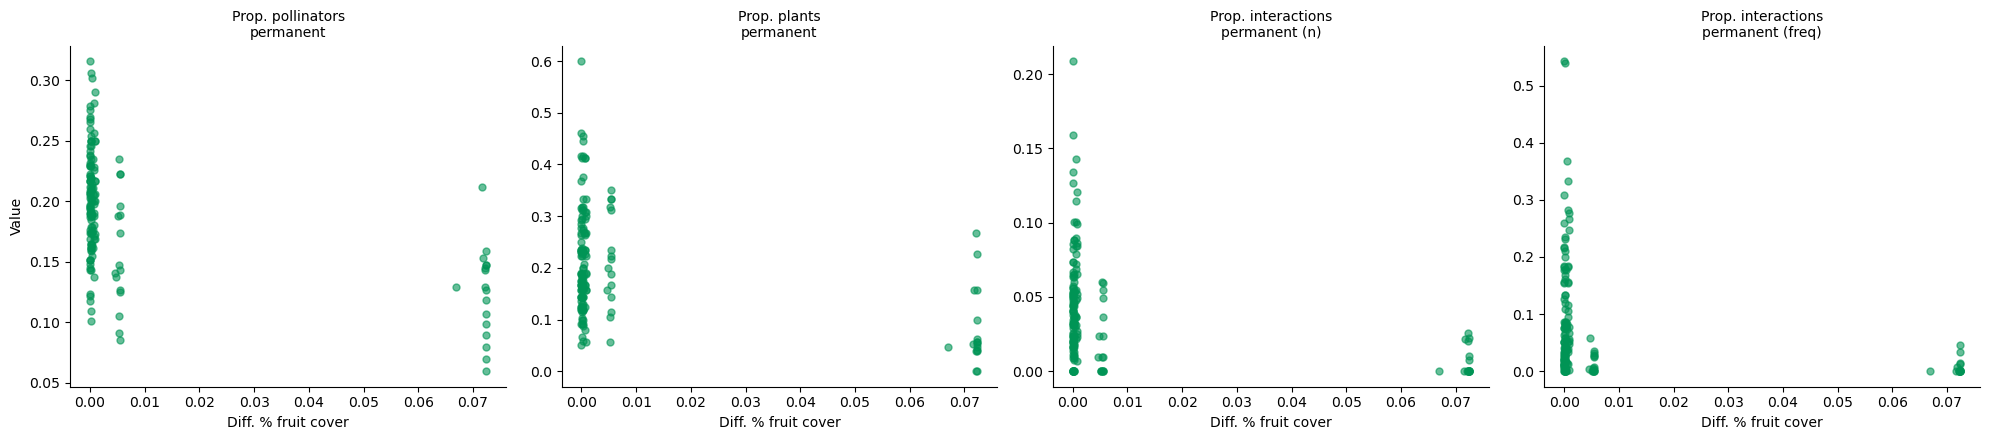

In [ ]:
import seaborn as sns
combined = (
    Spatial_Nodes_wide[['comparison', 'diff_fruit', 'poll_permanent_ratio', 'plant_permanent_ratio']]
    .merge(Spatial_Changes_n[['comparison', 'permanent_interactions_ratio']], on='comparison')
    .merge(Spatial_Changes_freq[['comparison', 'permanent_frequency_ratio']], on='comparison')
)

vars_ = ['poll_permanent_ratio', 'plant_permanent_ratio',
         'permanent_interactions_ratio', 'permanent_frequency_ratio']
titles = ['Prop. pollinators\npermanent', 'Prop. plants\npermanent',
          'Prop. interactions\npermanent (n)', 'Prop. interactions\npermanent (freq)']

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharex=True)

for ax, var, title in zip(axes, vars_, titles):
    ax.scatter(combined['diff_fruit'], combined[var], color='#009455', alpha=0.6, s=25)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Diff. % fruit cover')

axes[0].set_ylabel('Value')
sns.despine(fig=fig)
plt.tight_layout()

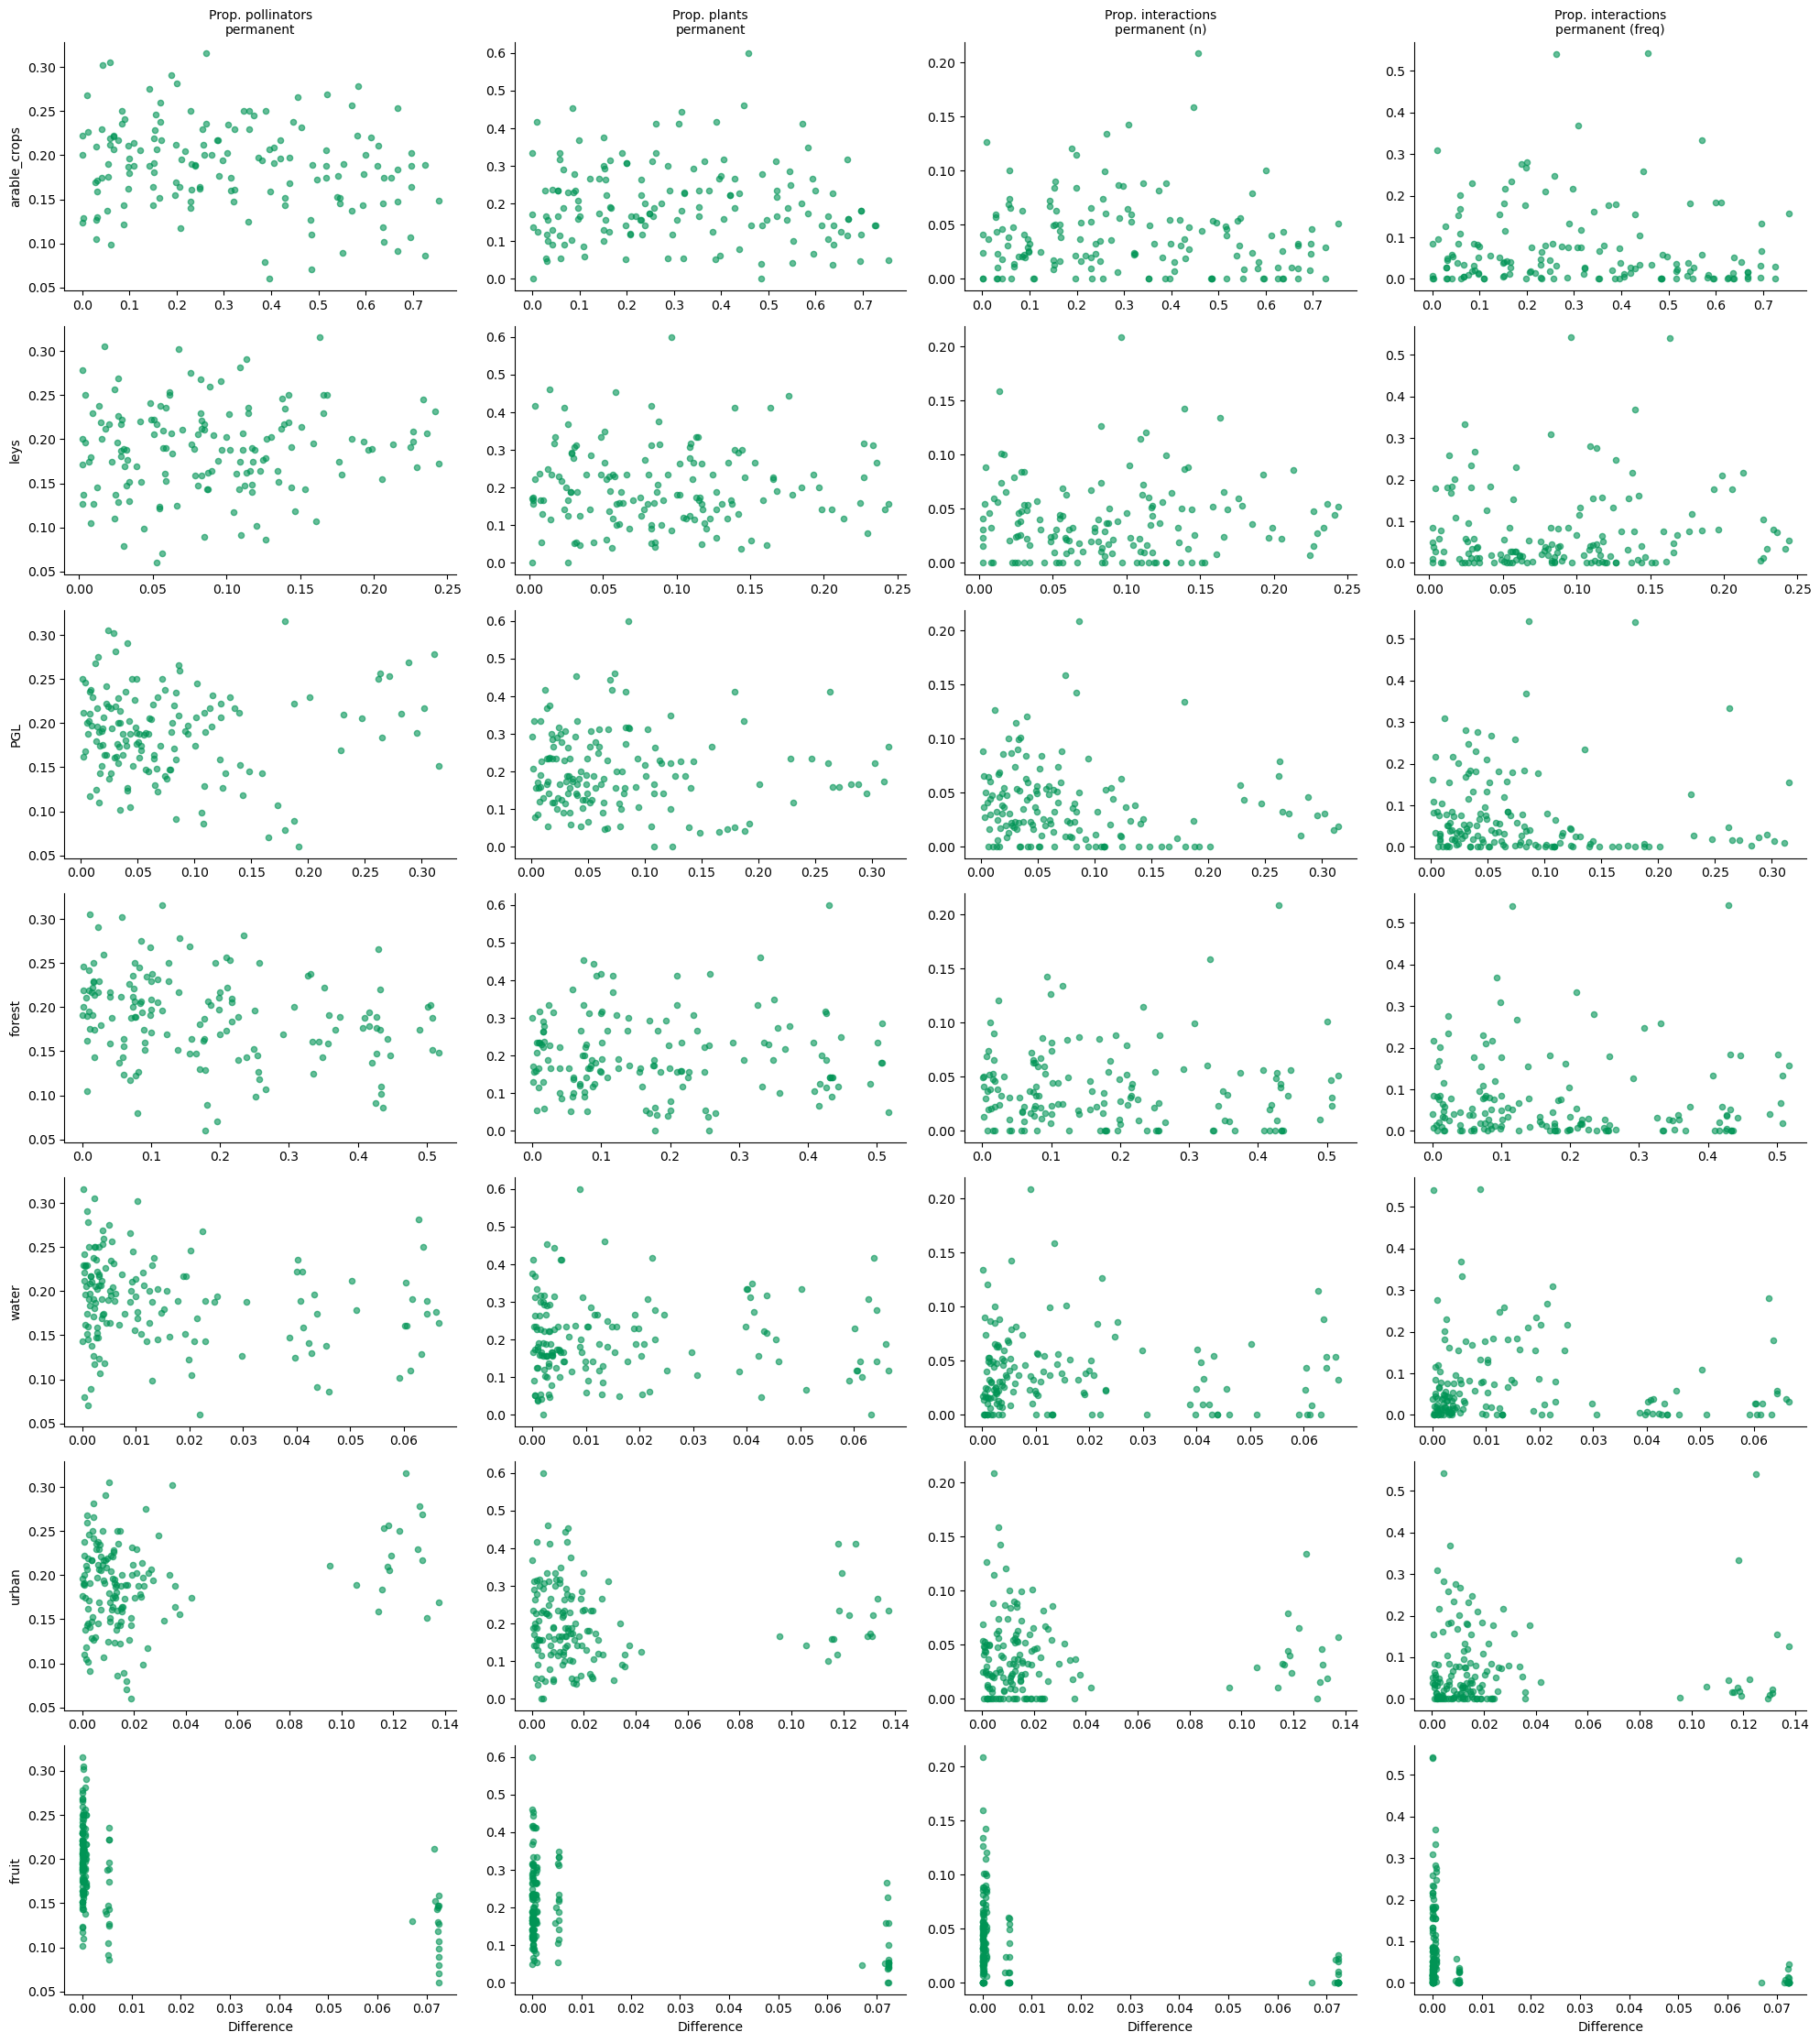

In [ ]:
landuse_cols = ['arable_crops', 'leys', 'PGL', 'forest', 'water', 'urban', 'fruit']
diff_cols = [f'diff_{c}' for c in landuse_cols]

vars_ = ['poll_permanent_ratio', 'plant_permanent_ratio',
         'permanent_interactions_ratio', 'permanent_frequency_ratio']
titles = ['Prop. pollinators\npermanent', 'Prop. plants\npermanent',
          'Prop. interactions\npermanent (n)', 'Prop. interactions\npermanent (freq)']

combined = (
    Spatial_Nodes_wide[['comparison'] + diff_cols + ['poll_permanent_ratio', 'plant_permanent_ratio']]
    .merge(Spatial_Changes_n[['comparison', 'permanent_interactions_ratio']], on='comparison')
    .merge(Spatial_Changes_freq[['comparison', 'permanent_frequency_ratio']], on='comparison')
)

fig, axes = plt.subplots(len(diff_cols), len(vars_),
                          figsize=(20, 3.2 * len(diff_cols)),
                          sharey='col')

for i, diff_col in enumerate(diff_cols):
    for j, (var, title) in enumerate(zip(vars_, titles)):
        ax = axes[i, j]
        ax.scatter(combined[diff_col], combined[var], color='#009455', alpha=0.6, s=20)
        if i == 0:
            ax.set_title(title, fontsize=10)
        if j == 0:
            ax.set_ylabel(diff_col.replace('diff_', ''), fontsize=10)
        if i == len(diff_cols) - 1:
            ax.set_xlabel('Difference')

sns.despine(fig=fig)
plt.tight_layout()

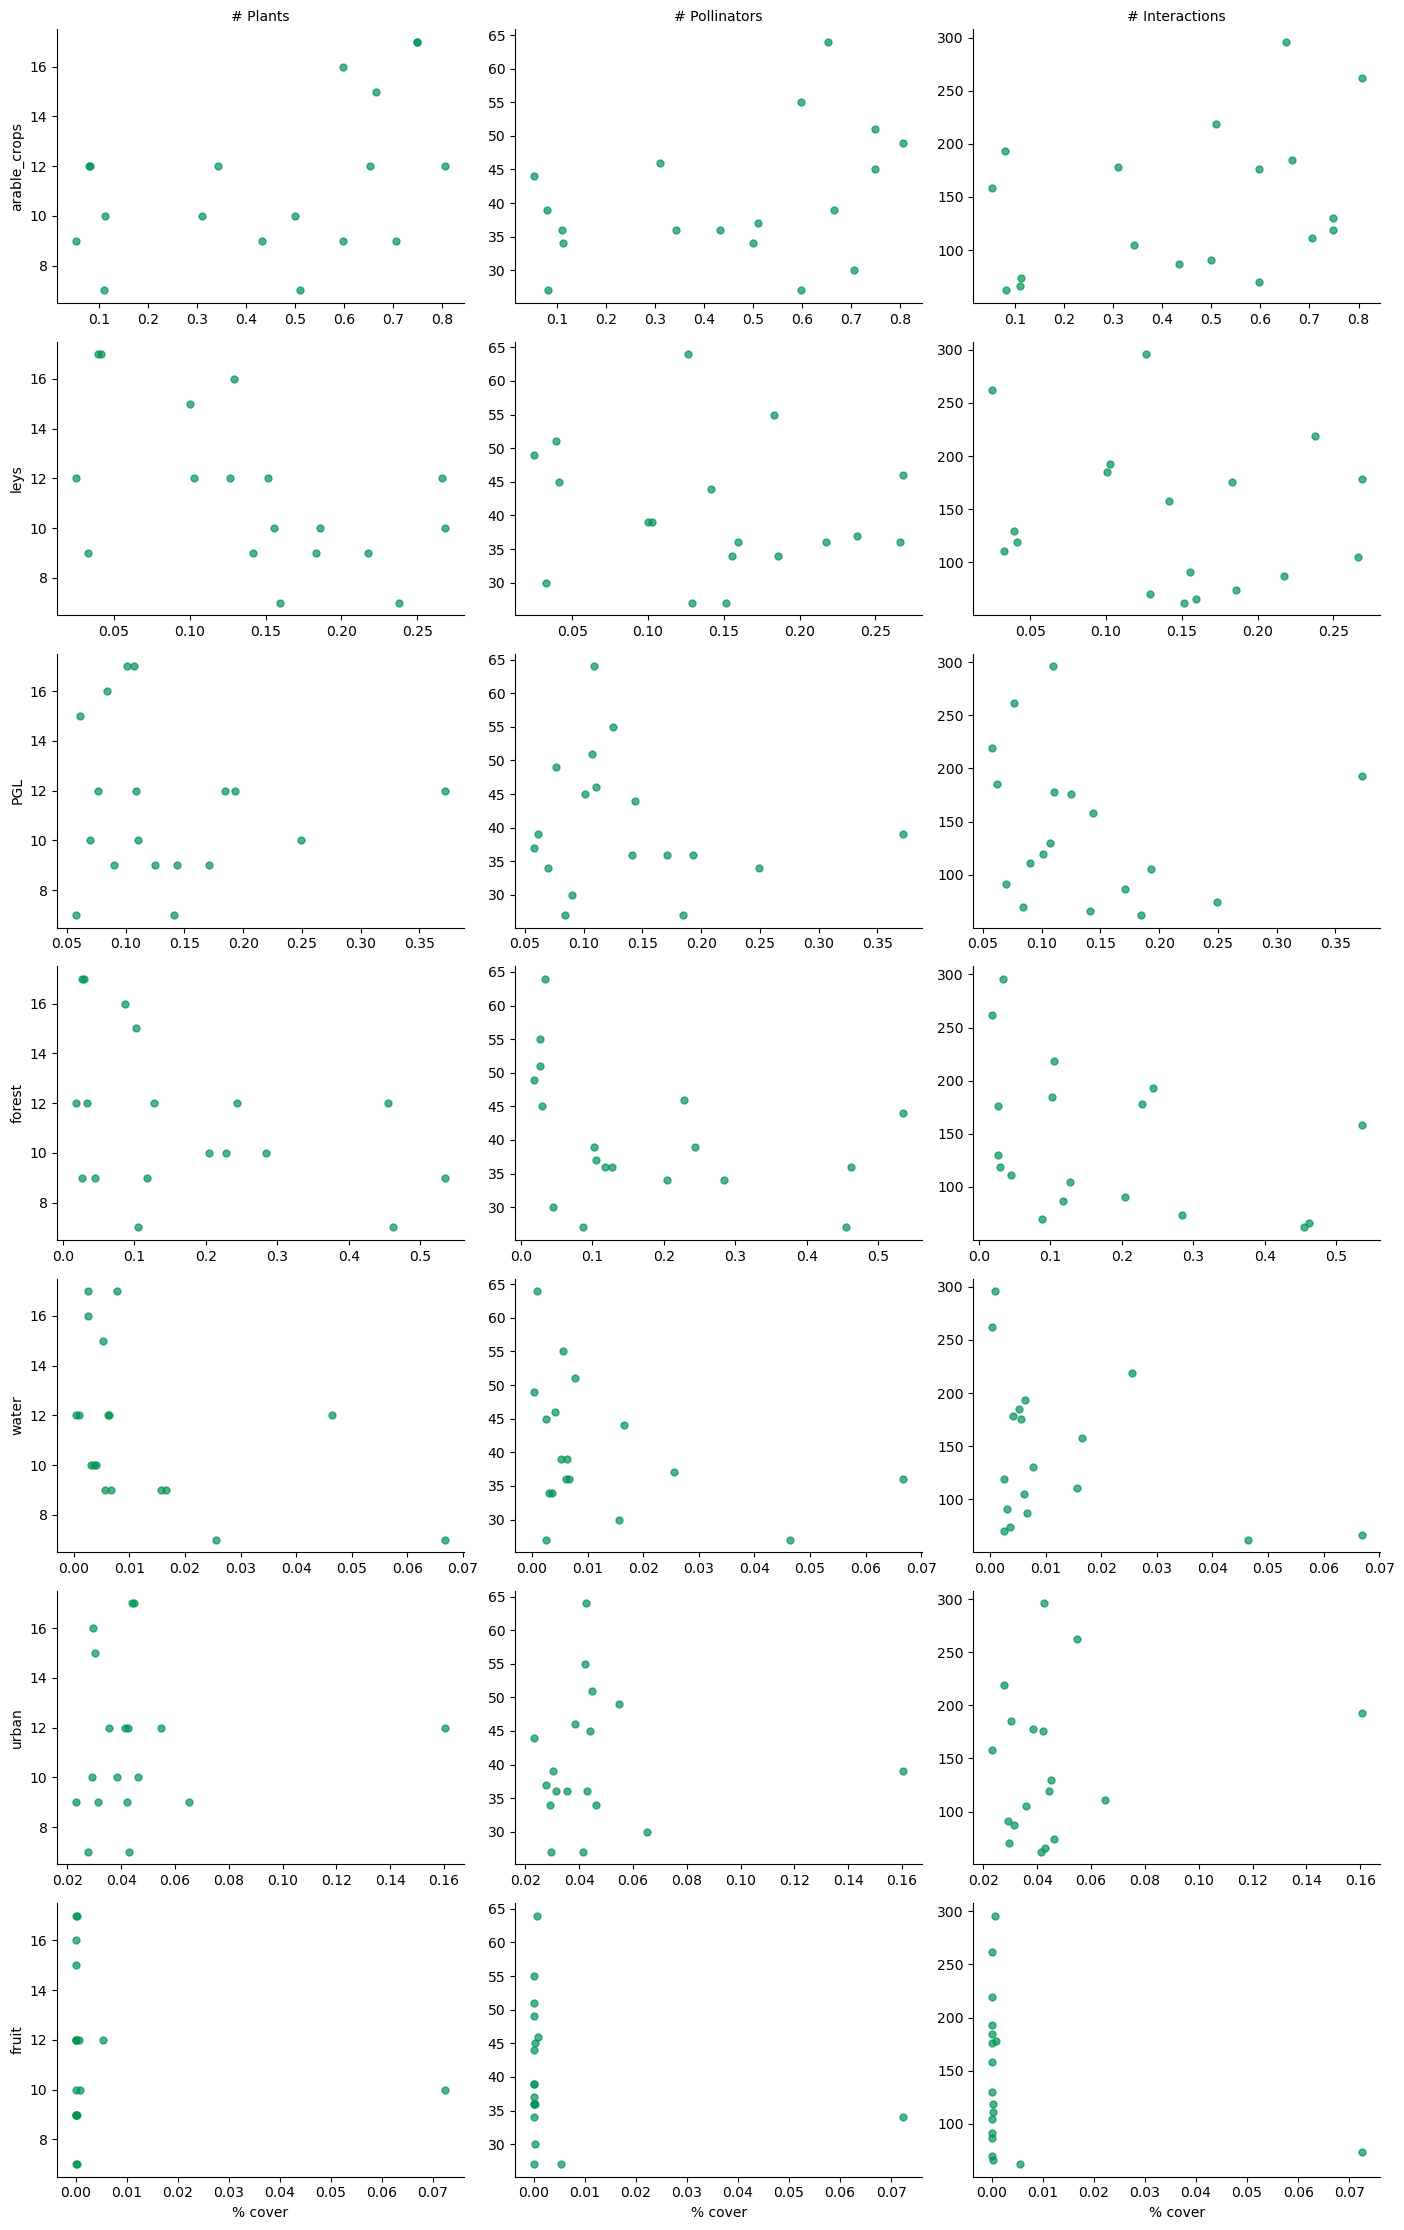

In [ ]:
landuse_cols = ['arable_crops', 'leys', 'PGL', 'forest', 'water', 'urban', 'fruit']

site_summary = network_summary.merge(
    df_1250.reset_index(), left_on='Network_id', right_on='id', how='left'
)

response_vars = ['n_plants', 'n_pollinators', 'n_interactions']
titles = ['# Plants', '# Pollinators', '# Interactions']

fig, axes = plt.subplots(len(landuse_cols), len(response_vars),
                          figsize=(14, 3.2 * len(landuse_cols)),
                          sharey='col')

for i, land_col in enumerate(landuse_cols):
    for j, (var, title) in enumerate(zip(response_vars, titles)):
        ax = axes[i, j]
        ax.scatter(site_summary[land_col], site_summary[var], color='#009455', alpha=0.7, s=25)
        if i == 0:
            ax.set_title(title, fontsize=10)
        if j == 0:
            ax.set_ylabel(land_col, fontsize=10)
        if i == len(landuse_cols) - 1:
            ax.set_xlabel('% cover')

sns.despine(fig=fig)
plt.tight_layout()